![title](images/LSSoQS_banner.png)

# Quantum Error Correction - In class exercises

State-of-the-art quantum computers have qubits that achieve single qubit error rates of $10^{-4}$ for single qubit gates and $10^{-3}$ for two qubit gates like the CNOT or CZ gates. However, if we want to run quantum algorithmes with real world impacts we need to perform anywhere from $10^9$ to $10^{12}$ operations requiring error rates below $10^{-9}$ to $10^{-12}$ respectively. From current understanding of physics it seams close to impossible to engineer physical qubits that meet those quality requirements, instead we will take a group of low quality qubits (those with error rates of $10^{-3}$ to $10^{-4}$) and get them to work together to create a few high quality qubits called logical qubits. This method is called Quantum Error Correction (QEC) and it will be the focus of this module to give you an intuition of how these QEC codes work in practice.

#### Key Intented Learning Outcomes:
* Gain an intuition of how QEC codes work to create high quality logical qubits
* How to use simulations to estimate the performance characteristics of a given code and predict the number of physical qubits are required to achieve a certain error rate on the logical qubits
* How QEC codes deals with non-Pauli errors

## Introduction

This module in the LSSoQC course will take place at the high-level quantum computing stack. More specifically we will be focusing on how to build a quantum circuit that turns many errors prone physical qubits into a few high-quality qubits that can be used in quantum algorithms.

Current state-of-the-art quantum computers have a lot of errors. The error rate of a single physical qubit is typically around $10^{-3}$ to $10^{-4}$ depending on the platform. However, if we want to use quantum computers to solve real world tasks we need much lower logical error rates, starting at $10^{-9}$ for small problems.

While the physical qubits in quantum computers will likely improve over time, it is however very unlikely - with current understanding - that the physical error rates will be able to be sufficiently small. The solution to this problem is quantum error correction which takes many faulty physical qubits and combines them into a few logical qubits which can have arbitrary low logical error rates (only limited by how many physical qubits that are being used per logical qubit).

Below you will get a short introduction to how you can combine physical qubits to create a logical qubit.

---

Most of the time when we talk about measurements on a quantum computer the talk about measuring a single qubit in the Pauli Z basis ($\ket0$ or $\ket1$). There are, however, a lot of other types of measurements that you could perform - like a single qubit measurement in the X or Y-basis instead of the Z-basis - an X-basis measurement could for example be achieved by applying a hadamard gate right before a measurement in the Z-basis since a Hadamard gate swaps the X and Z basis. But we are not even limited to single qubit measurements. With the right circuit setup, it is possible to measure the eigenvalue of a multiqubit Pauli operator. The circuit diagram below shows how you would measure the $\sigma_0\sigma_1\cdots\sigma_m$ multiqubit operator, with $\sigma_i \in {I_i, X_i, Y_i, Z_i}$ representing a Pauli operator (or identity) on qubit $i$.

<img src="images/multi-qubit-measurement.png" style="height: 300px; margin-right: 1em;">

Depending on how well you know your quantum algorithms, you may notice that this is an instance of the [Quantum Phase Estimation](https://pennylane.ai/qml/demos/tutorial_qpe) (**QPE**) algorithm, estimating the phase of $U=\sigma_0\sigma_1\cdots\sigma_m$ to one bit of precision. After such a multi-qubit measurement has been performed, up to 1 bit of information / entropy has been removed from the system. QECCs uses this to their advantage to remove the entropy, introduced by the errors, from the system without measuring gaining knowledge of the information stored in the logical qubit that we want to protect. The multi-qubit Pauli operators that the QECCs use to detect errors are called the stabilizers $g$ of the code.

A stabilizer $g$ of a QECC, by definition, acts in the following way on an error free logical state $\ket\psi$:

$$
g\ket\psi = \ket\psi
$$

In the case that an error $\epsilon$ (for now assumed to consist of one or more Pauli operators) act on the logical state ( $\ket\psi \rightarrow \epsilon\ket\psi$ ), that error will be detected by the stabilizers that it anticommutes with ( $g\epsilon = -\epsilon g$ ), since the anticommutation leads to a flip of that stabilizers eigenvalue as seen by:

\begin{align}
    \ket{+} \otimes \mathcal{E} \ket{\psi}
    =& \frac{1}{\sqrt{2}} \left( \ket{0} \otimes \mathcal{E} \ket{\psi} + \ket{1} \otimes \mathcal{E} \ket{\psi} \right) \nonumber\\
    \xrightarrow{\text{Apply controlled-}g}\hspace{1mm}& \frac{1}{\sqrt{2}} \left( \ket{0} \otimes \mathcal{E} \ket{\psi} + \ket{1} \otimes g \mathcal{E} \ket{\psi} \right) \nonumber\\
    =& \frac{1}{\sqrt{2}} \left( \ket{0} \otimes \mathcal{E} \ket{\psi} - \ket{1} \otimes \mathcal{E} g \ket{\psi} \right) \nonumber\\
    =& \frac{1}{\sqrt{2}} \left( \ket{0} \otimes \mathcal{E} \ket{\psi} - \ket{1} \otimes \mathcal{E} \ket{\psi} \right) 
    &&= \ket{-} \otimes \mathcal{E} \ket{\psi}.
\end{align}

Measuring all the stabilizers $g$ of the code will give us information about the error that has occured in the code. All these measurement combined make up the syndrome of the code - the syndrome being the dataset containing all the information we have about the errors on the code.

If our code involves $n$ qubits that hold the logical information which we will refer to as the data qubits, we need $n$ independent stabilizers $g$ to fully characterize the logical state. We of course do not want that since that would also mean we could not encode any logical information into the state. If we want a logical state that can hold the information of $k$ qubits we only want to use $n-k$ stabilizers for the error detection and the remaining $k$ stabilizers to measure the logical information of our $k$ logical qubits in the state. For this module we will only be using $k=1$ so we will always have one less stabilizer than the number of data qubits.

While we could in principle pick any set of $n-k$ independent stabilizers, in practice they are not all equally useful. We could for example pick $g_i=X_i$ for the first $n-k$ data qubits, and while this would allow us to detect any combination of Pauli Z errors on the first $n-k$ qubits, it would not allow us to detect any errors on the remaining qubits or Pauli X errors on any data qubit. To talk about how good a given set of stabilizers are we often talk about the code distance $L$. The code distance $L$ tells us how many single data qubit Pauli errors are needed to flip our logical state without the error being detected by any of our stabilizers. In the coding example we will look at two such choices of stabilizers.

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #4CAF50; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🖥️ Exercise</h4>

- In practice we will often use an odd distance for our code like 3, 5, 7, etc. Why do you think that we are usually not interested in the even code distances?

</div>

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #ccc; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>📝 Answer:</h4>

Your answer goes here...

</div>

## Coding example

For the coding examples and the exercises, we will use two popular Quantum Error Correction libraries, [`qecsim`](https://qecsim.github.io/) and [`stim`](https://quantum-journal.org/papers/q-2021-07-06-497/). 

`qecsim` is good to use when our goal is to know how a Pauli error on the code affects the stabilizers, however if we are instead interested in how the code performs under more realistic circumstances `stim` is the better option as it simulates the full circuit and allows for circuit level noise.

We will therefore start by importing both as well as some other standard python libraries:

In [4]:
import qecsim
import stim

import numpy as np
import matplotlib.pyplot as plt

from IPython.display import Markdown, display

# Some custom made helper functions
import helper_functions

For this first part we will only be using `stim`. You can find the documentation [here](https://quantum-journal.org/papers/q-2021-07-06-497/).

`stim` is a python library that can simulate a subset of quantum circuits really efficiently and fast. By a subset of quantum circuits we mean circuits that only use [Clifford gates](https://medium.com/qiskit/explore-the-clifford-group-a-crucial-tool-for-benchmarking-error-correction-and-more-b9fdca16bb46) which includes gates like the Pauli gates, Hadamard gate, CX, CZ and many more but not gates like $R_Z(\theta)$ or T. This means we `stim` can't simulate a universal quantum circuit but it can simulate the circuits used for quantum error correction. This restriction on which gates we can use allows stim to easily simulate quantum circuits with throusands of qubits - even on a laptop.

Since `stim` is so well suited for simulating quantum error correction, it already comes with a few quantum error correction codes implemented so we don't have to do that part of the work.

---

The first quantum error correction code we will take a look at is the repetition code with stabilizer $g_i = X_iX_{i+1}$ with $i\in{0,1,\cdots,L-2}$ giving us a code distance of $L$ under the assumption that only Pauli Z errors can happen on the data qubits.

In the $L=3$ case below the two stabilizes are $g_0 = X_0X_1$ and $g_1 = X_1X_2$, with the three data qubits labeled by $q_0$, $q_2$ and $q_4$ and the two qubits that measure the stabilizes labeled by $q_1$ and $q_3$.

In practice these measurements are not perfect so they will be repeated multiple times often on the order of $\mathcal O(L)$.

<div style="font-size: 1.18em; line-height: 1.3; border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #7e57c2; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🧠 How to read the quantum circuit</h4>

Here is a list of the quantum gates that appera in the above quantum circuit as well as the instructions that are <code>stim</code> specific.

- `R`: This will reset the qubit to the $\ket0$ state.
- `M`: This measures the qubit in the Z-basis. The measurement result is stored in the`rec[i]` variable.
- `MR`: This is a measurement of the qubit in the Z-basis followed by a reset to the $\ket0$ state.
- `●-⊕`: This is the CNOT gate, with the `●` being the control and the `⊕` being the target.
- `DETECTOR`: This returns the parity of one or more measurement records`rec[i]` (it is `1` if an odd number of `rec[i]` are `1`, and `0` otherwise).
- `OBS_INCLUDE(n)`: Like `DETECTOR`, but returns the logical observable instead of a stabilizer observable.
- `REP#`: Indicates that the part of the circuit inside the brackets `[]` should be repeated `#` times.

</div>

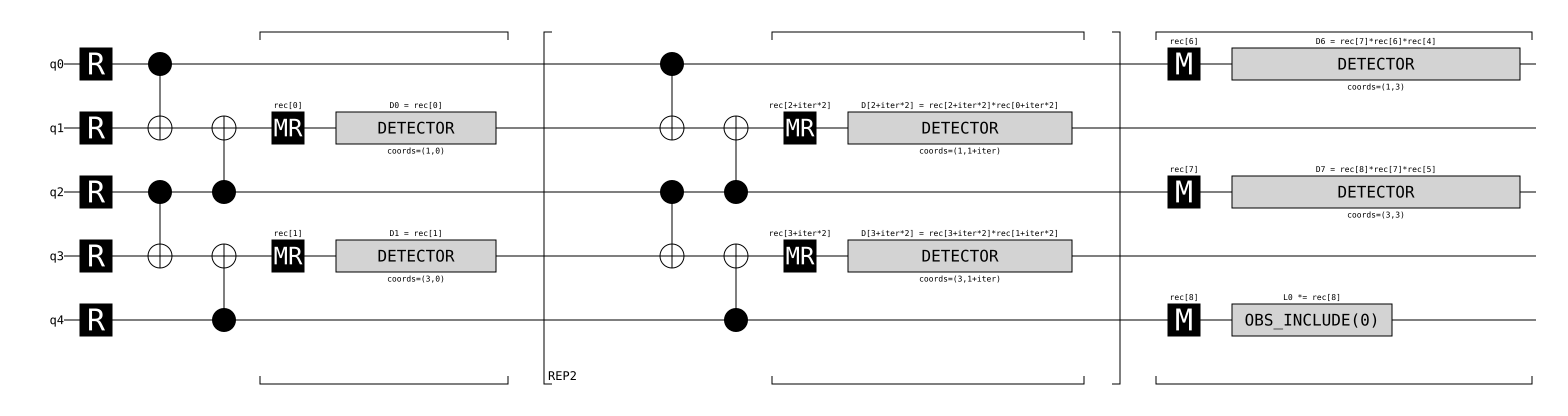

In [5]:
repetition_code = stim.Circuit.generated(
    "repetition_code:memory", 
    distance=3, # The code distance L
    rounds=3, # The number of rounds R
)

display(Markdown(filename="markdown_files/repetition_code_diagram.md"))
repetition_code.diagram("timeline-svg")

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #4CAF50; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🖥️ Exercise</h4>

Try to play around a bit with the `distance` and `rounds` settings to make sure they make sense to you.

</div>

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #ccc; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🔍 Observations:</h4>

Your observations goes here...

</div>

---

As mentioned, the repetition code can only detect Pauli Z errors - it could easily be switched to only detect only Pauli X errors by changing $g_i = X_iX_{i+1}$ into $g'_i = Z_iZ_{i+1}$ but the underlying problem would still be the same.

These two repetition codes can however be combined to create a QECC that can detect both Pauli X and Pauli Z errors and in turn also Pauli Y errors as Y = iXZ. This code is known as the surface code. We will be looking at a modern variant of it called the rotated surface code which only uses halve the number of qubits that the original surface code used without sacrificing performance. A picture of the distance 3 variant is shown in the picture below:

<img src="images/SurfaceCode.png" style="height: 500px; margin-right: 1em;">

Each stabilizer of the code is represented as a plaquette (colored area) of either X-type or Z-type, with X-type only using Pauli X stabilizers and Z-type only using Pauli Z stabilizers.

Just like with the repetition code, stim already have a built-in function which will create the circuit diagram for us.

<div style="font-size: 1.18em; line-height: 1.3; border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #7e57c2; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🧠 How to read the quantum circuit</h4>

- `Rₓ`: Resets the qubit in the X-basis to the $\ket+$ state.
- `Mₓ`: Measures the qubit in the X-basis.
- `COORDS(x,y)`: The 2d positioning the qubit as the surface code is a 2d code. (Has no effect on the qubit).

There are a few unused qubit lines in the diagram, theses should be ignored as they do not play a part in the code and are only there due to how stim underlying qubit numbering system

</div>

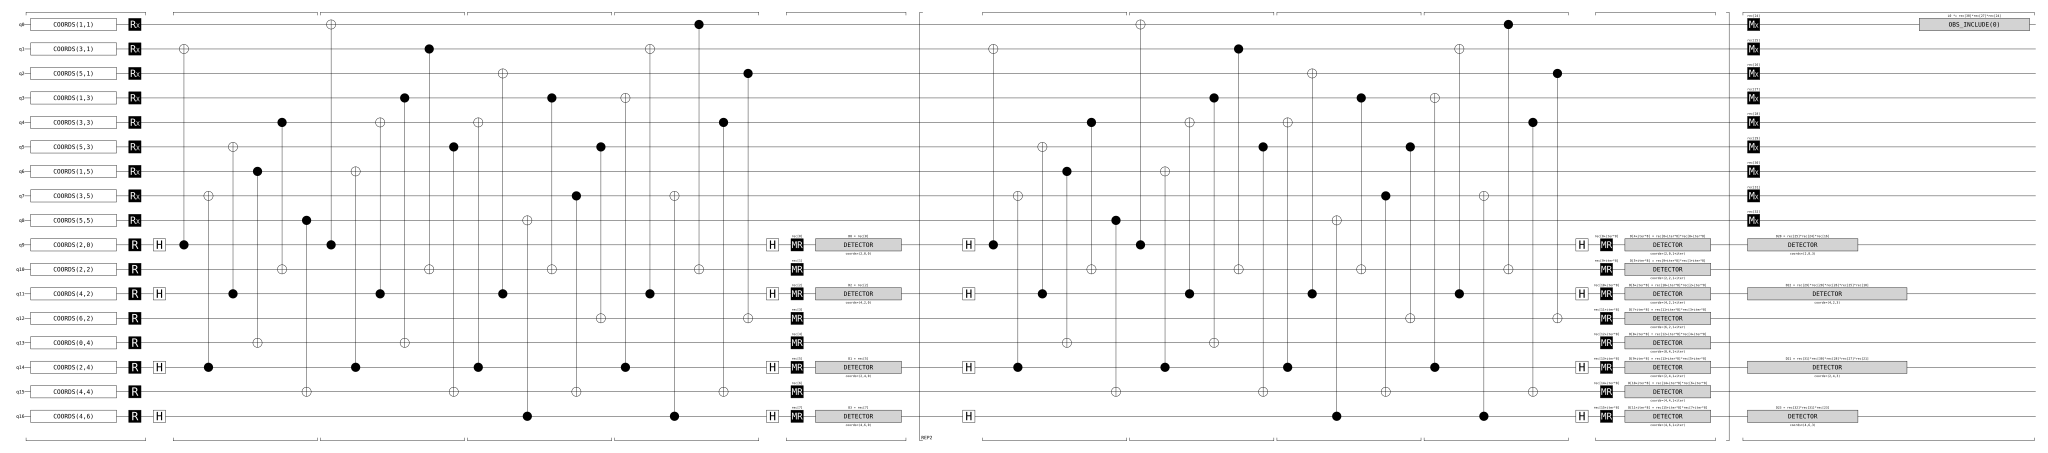

In [6]:
surface_code_circuit = stim.Circuit.generated(
    "surface_code:rotated_memory_x", # The _x indicates we initialize and measure in the X basis
    distance=3,
    rounds=3,
)
display(Markdown(filename="markdown_files/surface_code_diagram_1.md"))
helper_functions.sort_stim_qubit_order(surface_code_circuit).without_noise().diagram("timeline")

This may look a bit complicated at first, but this is only due to the 2d locations of the qubits are being compressed to a 1d line (the vertical axis). The next plot shows a much clearer way of displaying the quantum circuit diagram where it will become aparent that all the two-qubit gates are in fact local.

<div style="font-size: 1.18em; line-height: 1.3; border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #7e57c2; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🧠 How to read the time-slice diagram</h4>

A normal quantum circuit diagram uses one dimension (usually the vertical one) to place the qubits (horizontal lines) and another dimension (usually the horizontal one) to represent time. However, for QECC like the surface code which uses a 2d layout for the qubits, the standard quantum circuit diagram will not do a good job at representing the implementation of the code. The above diagram is much like the regular quantum circuit diagram, except it uses both the horizontal and vertical dimension to place the qubits and uses multiple plots to represent the flow of time (ticks). From the above time-slices it is much easier to see that all operations in the surface code are local, meaning they only interact with their nearest neighbors.

</div>

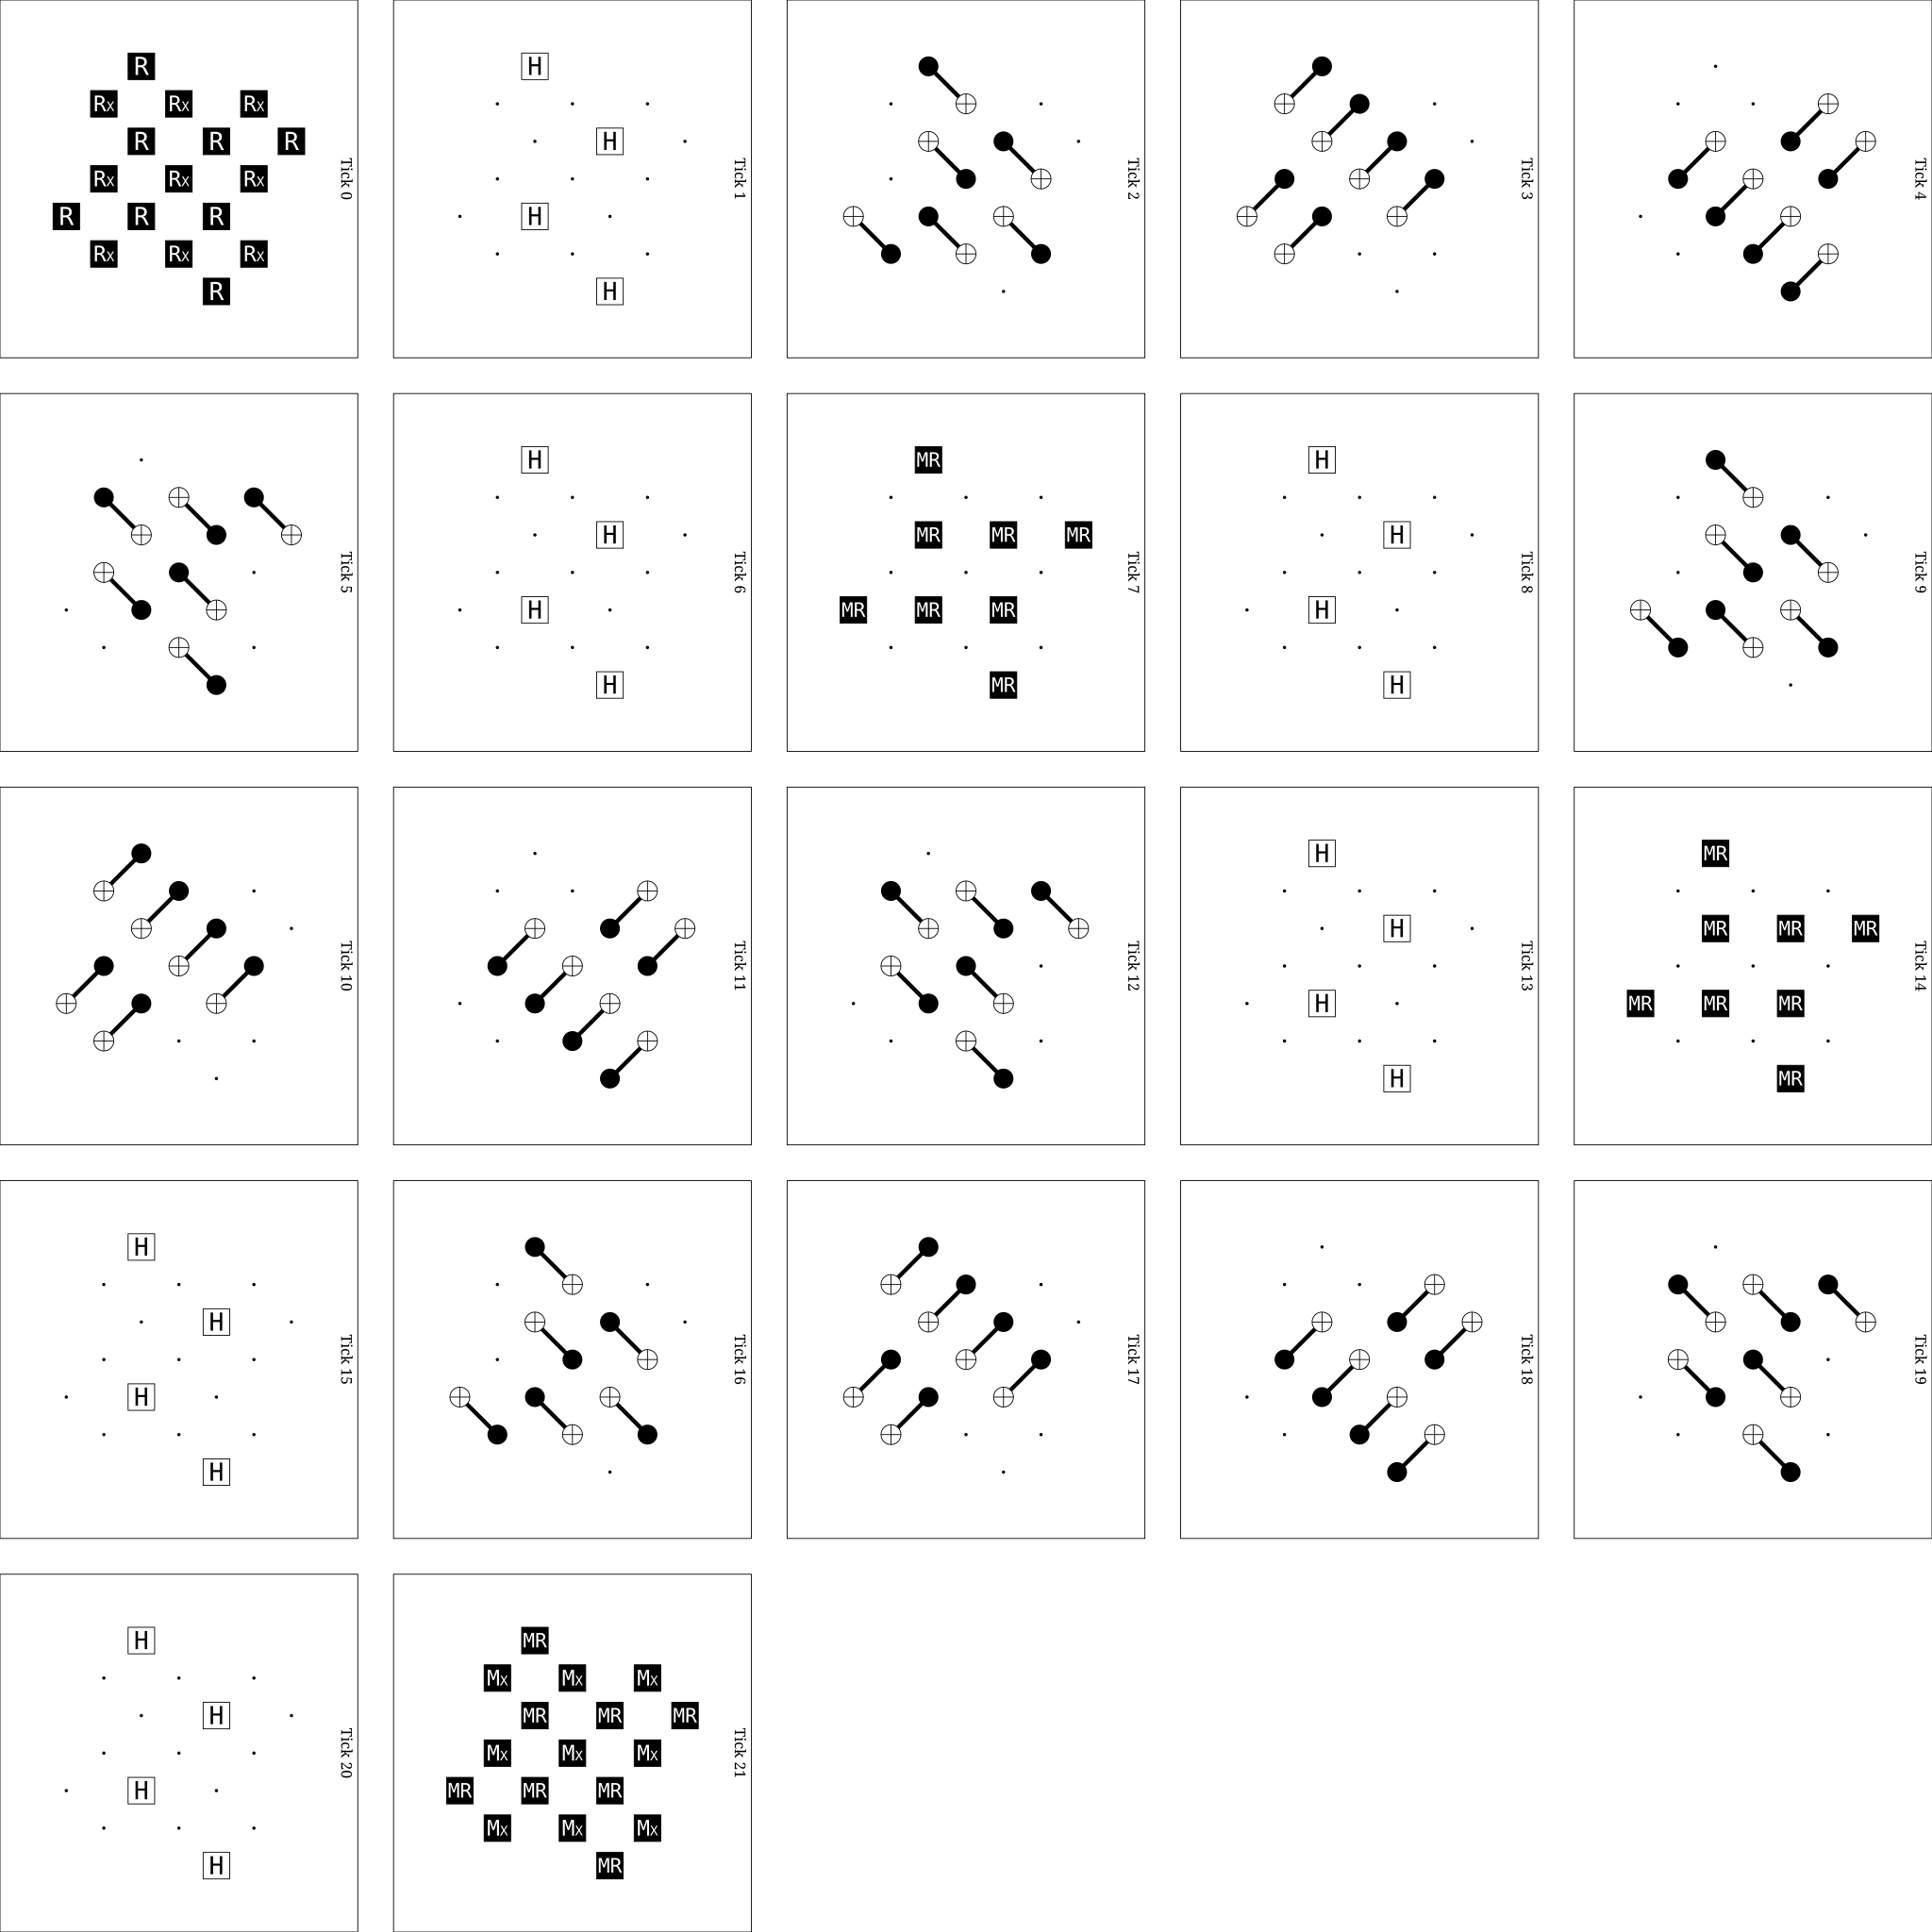

In [7]:
display(Markdown(filename="markdown_files/surface_code_diagram_2.md"))
# Set number of rows to a higher number to get a bigger picture and lower to get a more compact picture or leave as None to let stim decide.
surface_code_circuit.without_noise().diagram("timeslice-svg", rows=None)

The qubits that are measured each round (shown in Tick 7 and Tick 14) are the measurement of the stabilizers. The remaining qubits placed in a square `distance` by `distance` grid are the data qubits of the code. These are only measured at the end of the QECC to see if the logical observable has been flipped i.e. if there has been a logical error.

<details style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #e1f71fff; padding: 12px; border-radius: 6px; margin: 10px 0;">
  <summary><strong>🗒️ Note (CZ gates are transpiled to CX gates)</strong></summary>

The surface code consist both of X-type stabilizers of the form $g_{i,j} = X_{i,j}X_{i+1,j}X_{i,j+1}X_{i+1,j+1}$ ( $g_{i,j} = X_{i,j}X_{i+1,j}$ on the edges ) for $i+j = 0 \mod 2$, and Z-type stabilizers of the form $g_{i,j} = Z_{i,j}Z_{i+1,j}Z_{i,j+1}Z_{i+1,j+1}$ ( $g_{i,j} = Z_{i,j}Z_{i,j+1}$ on the edges ) for $i+j = 1 \mod 2$ also sometimes referred to as the X and Z plaquettes (ordered in a checkerboard pattern). `stim` has however chosen to turn the CZ gates for the Z-plaquettes into CX gates, by combining them with the Hadamard gates on the measurement qubits using the identity $\mathrm{CX_{2,1}} = (H\otimes I)\;\mathrm{CZ_{2,1}}\;(H\otimes I)$ also shown in the circuit diagram below:

<img src="images/CZ_to_CX.png" style="height: 150px; margin-top: 1em;">

</details>

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #4CAF50; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🖥️ Exercise</h4>

- Once again, play around with the `distance` and `rounds` settings to get a better intuition of how the code is structured.</li>
- Can you spot what changes between the `"surface_code:rotated_memory_x"` and `"surface_code:rotated_memory_z"` settings in the time-slice diagram? You may have to look closely at the first and last tick.

</div>

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #ccc; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>📝 Answer:</h4>

Your answer goes here...

</div>

---

### Estimating the Logical Error Rate of a QECC like the surface code

We will start by explaining what we mean by error rates.

When we talk about physical error rates we talk about the probability that an error occured on a physical qubit (one of the qubits that make up the QECC). But on what timescale? The physical error rate often refers to how likely each operation is to fail - the probability may depend on the operation (a measurement operation may be more likely to produce a wrong measurement than a hadamard gate is to introduce an error), in our case we will however use the same probability for every operation.

The Logical Error Rate, often abreviated to **LER**, refers to how likely we are to see an error on our logical qubit. While physical error rates refered to the probability that each operation will fail - LER refers to the probability that where has been an error on the logical qubit during the entire duration of the QECC that we did not predict based on the syndrome measurements produced during the QECC.

With that out of the way it is now time to estimate this LER using simulations.

We start by creating a QECC with circuit level errors - meaning each operation has a chance of introducing a Pauli error to the circuit. In this case we will use the distance 5 surface code with 5 rounds of measurements.

In [8]:
distance = 5
rounds = 5
basis = 'z' # 'x' or 'z'
p = 0.01 # Set relatively high to better see the errors
# This would be a single qubit in the code with this error rate

surface_code_circuit = stim.Circuit.generated(
    f"surface_code:rotated_memory_{basis.lower()}",
    distance=distance,
    rounds=rounds,
    before_round_data_depolarization=p, # With probability p, place a random Pauli error on a given data qubit before each round
    after_clifford_depolarization=p, # With probability p, apply a random Pauli error after each gate on the qubits used by that gate (excluding resets and measurements)
    after_reset_flip_probability=p, # With probability p, flip the state of the qubit (apply X if the qubit was reset into the Z-basis and Z if it was reset into the X-basis)
    before_measure_flip_probability=p # With probability p, flip the result of a qubit measurement
)

To estimate the LER of any QECC we will first need some data. We can get measurement data using the `sampler` object provided by `stim`. Here we will be using the detector sampler which will tell us which detectors (the ones shown in the circuit diagram a few cells above) triggered during the code. If no errors occured on the code, no detectors will trigger per definition.

In [9]:
sampler = surface_code_circuit.compile_detector_sampler()
detector_events, observable_flips = sampler.sample(shots=10, separate_observables=True)
k = distance**2 - 1 # Number of stabilizer measurements per round

display(Markdown(filename="markdown_files/detector_outcomes.md"))
for c, data in enumerate(detector_events):
    print(f"\nData for shot {c}:")
    print("Round 0 (Initialization):","".join("1" if s else "_" for s in data[:k//2]))
    for r in range(1, rounds):
        print(f"Round {r} (internal round):","".join("1" if s else "_" for s in data[r*k - k//2:(r+1)*k - k//2]))
    print(f"Round {rounds} (final round):   ","".join("1" if s else "_" for s in data[rounds*k - k//2:]))
    print("Data qubit measurement indicates:", "No logical error" if observable_flips[c] == 0 else "A logical error")

<div style="font-size: 1.18em; line-height: 1.3; border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #7e57c2; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🧠 How to understand the output above</h4>

The above output shows which detectors reacted at each round of the QECC. An `_` means no reaction, while a `1` means a detection / change in syndrome measurement. Generally speaking, a `1` in the same location on two consecutive rounds tells us a measurement error occurred on that syndrome and no errors on the data qubits the measurement is connected to. On the other hand, two `1`'s next to each other indicates a Pauli error on the data qubit shared by those detectors, since a Pauli error on a single data qubit activates is detected by two separate stabilizers (unless the error is on the edge of the code).

</div>


Data for shot 0:
Round 0 (Initialization): _1_11_______
Round 1 (internal round): ___1_____11___1__1111___
Round 2 (internal round): __________1____1___11___
Round 3 (internal round): ____1______1___1____1___
Round 4 (internal round): _1_1_11__11___1_________
Round 5 (final round):    ______1_____
Data qubit measurement indicates: No logical error

Data for shot 1:
Round 0 (Initialization): ________1___
Round 1 (internal round): ____1____1_1__1___1__1__
Round 2 (internal round): ___1____1_1_11__________
Round 3 (internal round): _________1__1___________
Round 4 (internal round): 1_1______1__1___________
Round 5 (final round):    ____________
Data qubit measurement indicates: A logical error

Data for shot 2:
Round 0 (Initialization): __1_1_1_____
Round 1 (internal round): _1_1____________________
Round 2 (internal round): ____________1_______1___
Round 3 (internal round): ____________1_____1_1___
Round 4 (internal round): ______________1_____1___
Round 5 (final round):    _____1______

The actual problem is however quite a bit more complicated as any combination of these things could have happened. The job of any QECC decoder is therefore to figure out what happened based on the detection events. 

There a many ways of implementing such a decoder and the implementation of the decoder plays a big part in how well the QECC will perform. Some implementations use tensor networks, some use graph networks, some use neural networks to name a few. The decoder we will be using here - based on a graph network - is the one provided in the [`PyMatching`](https://dl.acm.org/doi/full/10.1145/3505637) library which implements an open-source version of the widely used [Minimum Weight Perfect Matching](https://www.cambridge.org/core/journals/canadian-journal-of-mathematics/article/paths-trees-and-flowers/08B492B72322C4130AE800C0610E0E21) decoder.

The decoder doesn’t need to reconstruct the exact physical error that occurred, since many different errors can have the same effect on the code (see the note box for details). Instead, its task is to find any Pauli string that produces the same syndrome as the observed one. If the decoder selects the most likely such Pauli string, it will most likely produce the same logical effect as the true error. In that case, this Pauli string can serve as a useful proxy for determining whether a logical error has occurred, allowing us to fix it without measuring the logical state.

<details style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #e1f71fff; padding: 12px; border-radius: 6px; margin: 10px 0;">
  <summary><strong>🗒️ Note (Equevalence of physical errors on the code)</strong></summary>

If you remember back to the begining of this notebook where stabilizers $g$ where introduced, we stated that $g\ket\psi = \ket\psi$. This however also implies that the physical error $\mathcal E$ has the same effect on our quantum state as the error $\mathcal E g$ has, since $g$ acts as identity on $\ket\psi$. In the case of the surface code where we have $L^2 - 1$ independent stabilizers $g$ we have $2^{L^2 - 1}$ ways of selectively applying the stabilizers giving us a total of $2^{L^2 - 1}$ physical error that has the same effect on $\ket\psi$ as the $\mathcal E$ error has.

Thus, as long as the decoder comes up with one of those $2^{L^2 - 1}$ corrections the code will be corrected correctly.

</details>


In [10]:
from pymatching import Matching as MWPM

The MWPM decoder can be set up based on the detector error model provided by `stim`. An example of how it works is shown below:

In [11]:
detector_error_model = surface_code_circuit.detector_error_model(decompose_errors=True)
mwpm = MWPM.from_detector_error_model(detector_error_model)
predictions = mwpm.decode_batch(detector_events)

for pred, actual in zip(predictions, observable_flips):
    print(f"MWPM prediction: {pred} (actual: {actual.astype(int)})")

MWPM prediction: [0] (actual: [0])
MWPM prediction: [0] (actual: [1])
MWPM prediction: [1] (actual: [1])
MWPM prediction: [0] (actual: [0])
MWPM prediction: [0] (actual: [0])
MWPM prediction: [1] (actual: [1])
MWPM prediction: [0] (actual: [0])
MWPM prediction: [0] (actual: [0])
MWPM prediction: [1] (actual: [1])
MWPM prediction: [0] (actual: [0])


<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #4CAF50; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🖥️ Exercise</h4>

Play around with the physical error rate (`p` from 3 cells above) and observe what happens to both the rate of 1s in the actual observable and the rate of wrongful predictions by the MWPM decoder.

</div>

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #ccc; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🔍 Observations:</h4>

Your observations goes here...

</div>

As you can see the MWPM decoder is relatively good a predicting whether a logical error occurred based on the detection events (as long as you did not choose `p` to large).

However, if we want to get an estimate of the Logical Error Rate (**LER**) we need a lot of shots / experiments. To not have to repeat the code each time we want to test a new configuration of the surface code we will put it all into a function:

In [12]:
def estimate_logical_error_rate(circuit: stim.Circuit, num_shots: int) -> float:
    """
    Estimate the logical error rate of a QECC quantum circuit.

    Args:
        circuit (stim.Circuit): The quantum error-correcting code circuit to simulate.
        num_shots (int): The number of shots to simulate.
    
    Returns:
        float: The estimated logical error rate (LER).
    """
    # Sample the circuit.
    sampler = circuit.compile_detector_sampler()
    syndromes, observable_flips = sampler.sample(num_shots, separate_observables=True)

    # Configure a decoder using the circuit.
    detector_error_model = circuit.detector_error_model(decompose_errors=True)
    mwpm = MWPM.from_detector_error_model(detector_error_model)

    # Run the decoder.
    predictions = mwpm.decode_batch(syndromes)

    # Compute the error rate.
    error_rate = np.mean(observable_flips != predictions)
    return error_rate

Let's set up a more realistic error rate for the surface code and estimate its logical error rate based on 100 000 experiments

In [13]:
p = 0.001 # Use a more realistic error rate

surface_code_circuit = stim.Circuit.generated(
    "surface_code:rotated_memory_z",
    distance=distance,
    rounds=rounds,
    after_clifford_depolarization=p,
    before_round_data_depolarization=p,
    before_measure_flip_probability=p,
    after_reset_flip_probability=p
)

ler = estimate_logical_error_rate(surface_code_circuit, 100_000)

print(f"Physical error rate:       {p:6.3%}")
print(f"Logical Error Rate (LER):  {ler:6.3%}")

Physical error rate:       0.100%
Logical Error Rate (LER):  0.016%


<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #4CAF50; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🖥️ Exercise</h4>

Try to play a bit around with the physical error rate `p` to get an intuition of how the LER changes.

(In **Exercise 1** you will get a chance to do this more systematically)

</div>

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #ccc; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🔍 Observations:</h4>

Your observations goes here...

</div>

## Coding exercises

### Exercise 1 - Threshold of the surface code

If we want to build a practically useful quantum computer, we need to have logical qubits that have a low Logical Error Rate (**LER**). There are two main ways to decrease the LER of a logical qubit, one way is to just use better physical qubits. If the physical qubits that make up the logical qubit fail less frequently, they are less likely to cause enough errors that our decoder will predict the wrong correction - leading to a logical error. The other way to decrease the logical error rate is by increasing the distance of the code - if more single qubit errors are needed to cause a logical error, the LER will naturally be lower. This however only works if the physical qubit error rate is already below some threshold $p_{thr}$ as you will see in a moment.

In the case of the surface code, the relation between physical error rate and LER roughly goes as (only valid for small $p$. $p$ can be assumed small if it is below $5\times10^{-3}$):

$$
\begin{equation}
\text{LER} \approx \left(\frac{p}{p_{thr}}\right)^{(L+1)/2}
\end{equation}
$$

This exercise will be focused on estimating $p_{thr}$ through simulations of the surface code.

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #4CAF50; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🖥️ Exercise</h4>

Estimate the LER for physical error rates between $10^{-3}$ and $2\times10^{-2}$ (something like ``np.logspace(-3, -1.5, 20)``) and code distances 3, 5 and 7, using the `estimate_logical_error_rate(circuit: stim.Circuit, num_shots: int) -> float` function

<details style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #e1f71fff; padding: 12px; border-radius: 6px; margin: 10px 0;">
  <summary><strong>🗒️ Note (tqdm progress bar)</strong></summary>

Some of this code can take quite some time to complete (several minuites depending on hardware) so adding a progress bar might come in handy to get an idea of whether or not it will take too long for it to finish.

An easy way of adding a progress bar is with `tqdm`. Below is a code example of how to use it:

```python
from tqdm import tqdm
for val in tqdm(range(500), desc="name of progress bar", ncols=150):
    pass
```

or with a numpy array:

```python
from tqdm import tqdm
vals = np.logspace(-3, -1.5, 20)
for val in tqdm(vals, desc="name of progress bar", ncols=150):
    pass
```

</details>

</div>

In [14]:
# Your code goes here

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #4CAF50; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🖥️ Exercise</h4>

- Plot the data and visually estimate the value of $p_{thr}$

<details style="margin: 10px 0; padding: 8px 12px; border: 1px dashed var(--jp-border-color2, #aaa); border-radius: 6px;">
  <summary><strong>💡 Hint</strong></summary>

From Eq. (1), what can be said about the value of $\text{LER}$ when $p = p_{thr}$?

</details>

</div>

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #ccc; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>📝 Answer:</h4>

Your answer goes here...

</div>

In [15]:
# Your code goes here

# Suggestion: 
# - The plot will look nicer if you use log scale for both axes. You can do that with plt.loglog()
# - If you want errorbars on the data points, you can compute them as sqrt(ler * (1 - ler) / shots_per_setting) and plot them with plt.errorbar() https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.errorbar.html

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #4CAF50; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🖥️ Exercise</h4>

Fit Eq. (1) to the plotted data to get a better estimate of $p_{thr}$. Remember to only fit to the data that is below your estimated $p_{thr}$ as Eq. (1) is not valid for $p > p_{thr}$.

<details style="margin: 10px 0; padding: 8px 12px; border: 1px dashed var(--jp-border-color2, #aaa); border-radius: 6px;">
  <summary><strong>💡 Hint</strong></summary>

To fit all three data series, it might be helpful to fit a function of two variables $\text{LER} = f(p, L)$ instead of fitting them individually.

</details>

<details style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #e1f71fff; padding: 12px; border-radius: 6px; margin: 10px 0;">
  <summary><strong>🗒️ Note (example fitting tool)</strong></summary>

You are welcome to use whatever fitting tool you want - if you however do not know a good fitting tool to use you can use `iminuit`. Documentation found [here](https://scikit-hep.org/iminuit/).

`iminuit` allows you to fit to a custom function and get an estimated error on you fitting parameters based on the errors on you data points.

1) Import it like this:

    ```python
    from iminuit import Minuit
    from iminuit.cost import LeastSquares
    ```

2) Define your `model` as a function where the first argument is `x` and the following arguments are the fitting parameters in the function you are fitting; the output of the function is when `y`. Note that `x` can also be a tuple if you are fitting a multi-variable function.

3) Fit the model using least square after calculating the `y_error` for each of your data-points.

    ```python
    least_square = LeastSquares(x, y, y_err, model)
    m = Minuit(least_square, p_thr=1, c=1)
    m.migrad() # Run minimization
    display(m) # Show the fitting result
    ```

4) Get the results of your fit:

    ```python
    values_dict = m.values()
    errors_dict = m.errors()
    ```

</details>

</div>

In [16]:
# Your code goes here

### Exercise 2 - How are Pauli errors detected

For this part, we will consider the effect a given set of Pauli errors has on the stabilizers of the surface code. We could do this using the `stim` library that we have been using so far, this would however involve turning off the built-in noise model stim's surface code comes with and then manually modifying the circuit to input a specific set of Pauli errors. On the other hand, `qecsim` offers a simpler method, allowing us to represent the set of Pauli errors in its "*binary symplectic representation*" (a binary vector of size $2n$ for $n$ data qubits, first $n$ elements mark data qubits with Pauli X error, and second $n$ elements data qubits with Pauli Z errors) and multiply it by a parity check matrix $\mod 2$ to get the syndrome vector. Exactly what we would have gotten if we had used `stim` but much more easily.

We start by importing `qecsim`'s implementation of the surface code. The documentation for `qecsim` can be found [here](https://qecsim.github.io/).

Unlilke `stim`, `qecsim` will not be able to simulate quantum circuits of any kind. Instead, it takes a more mathematical approach to quantum error correction by representing errors on data qubits as a vector $\mathcal E$ and the QECC as a matrix $\mathcal H$ that transforms the error into the syndrome of the code $\mathcal S$:

$$
\mathcal S = \mathcal H \mathcal E \mod 2
$$

In [21]:
from qecsim.models.rotatedplanar import RotatedPlanarCode

Below, we define a function which takes in a 2d array of letters `I`, `X`, `Y` and `Z`, and interpretate them as Pauli errors on the data qubits in the surface code, converting it to the "*binary symplectic representation*" `stim` uses, calculating the syndrome vector and plotting the result for easier interpretation. This function has been defined in the below cell - you do not need to wory about the exact implementation as that is not important for this module but you are of course welcome to take a look if you are interested.

In [22]:
from matplotlib.patches import Rectangle, Circle, Patch

def plot_pauli_errors_and_their_syndromes(errors: np.ndarray):
    """
    Plots a 2D array of Pauli errors and their resulting syndromes on a surface code.
    
    Args:
        errors (np.ndarray): A 2D numpy array of shape (L, L) where each element is one of "I", "X", "Y", or "Z".
    """
    errors = errors[::-1] # Reverse for more intuitive display (will now appear in the same way as in stim)

    # Create the qecsim surface code corresponding to the shape of the provided errors array (does not need to be square like the ones in stim)
    distance_r = errors.shape[0]
    distance_c = errors.shape[1]
    surface_code = RotatedPlanarCode(distance_r, distance_c)

    # Turn the Pauli errors into a binary symplectic representation which qecsim expects
    errors_bsr = np.array(
        [1 if e in ["X", "Y"] else 0 for row in errors for e in row] + 
        [1 if e in ["Z", "Y"] else 0 for row in errors for e in row]
    )
    # Compute the syndrome that results from these errors
    syndrome = surface_code.stabilizers @ errors_bsr % 2

    # Get coordinates for plotting
    plaquette_coords = surface_code._plaquette_indices
    data_qubit_coords = [(x-.5, y-.5) for y in range(distance_r) for x in range(distance_c)]

    # Scale figure size based on code distance
    size_r = (distance_r + 1.2) * .8
    size_c = (distance_c + 1.2) * .8
    plt.figure(figsize=(size_c*2, size_r))

    # Draw the surface code lattice
    for (x, y) in plaquette_coords:
        if x == -1:
            plt.gca().add_patch(Circle(
                (x+.5, y), .5,
                facecolor='#80b3ffff', 
                edgecolor=None,
                zorder = -1
            ))
        elif x == distance_c - 1:
            plt.gca().add_patch(Circle(
                (x-.5, y), .5,
                facecolor='#80b3ffff', 
                edgecolor=None,
                zorder = -1
            ))
        elif y == -1:
            plt.gca().add_patch(Circle(
                (x, y+.5), .5,
                facecolor='#ff8080ff', 
                edgecolor=None,
                zorder = -1
            ))
        elif y == distance_r - 1:
            plt.gca().add_patch(Circle(
                (x, y-.5), .5,
                facecolor='#ff8080ff', 
                edgecolor=None,
                zorder = -1
            ))
        else:
            plt.gca().add_patch(Rectangle(
                (x-0.5, y-0.5), 1, 1, 
                facecolor='#ff8080ff' if (x + y) % 2 == 0 else '#80b3ffff', 
                edgecolor=None
            ))

    # Draw connections between plaquettes and data qubits
    for (px, py) in plaquette_coords:
        for (qx, qy), err in zip(data_qubit_coords, errors.flatten()):
            if abs(px - qx) + abs(py - qy) == 1:
                is_x_connection = (px + py) % 2 # 0 for X-plaquettes, 1 for Z-plaquettes
                color = {
                    "I": ['w', 'w'],
                    "X": ['w', 'b'],
                    "Y": ['r', 'b'],
                    "Z": ['r', 'w'],
                }[err][is_x_connection]
                if color != 'w':
                    plt.plot([px, qx], [py, qy], color=color, lw=2)

    # Highlight syndromes and data qubit errors
    if sum(syndrome) > 0:
        plt.plot(*zip(*[coord for s, coord in zip(syndrome, plaquette_coords) if s]), 'g*', ms=30, label='Detections')
    
    # Annotate data qubit errors
    for (x, y), e in zip(data_qubit_coords, errors.flatten()):
        if e == "I":
            continue
        plt.text(x, y, e, fontsize=30, ha='center', va='center', color='black', bbox=dict(
            boxstyle="round,pad=0.1,rounding_size=0.4",
            facecolor='#ffffffbb', edgecolor='gray'
        ))

    # Plot all qubits in the code
    plt.plot(*zip(*data_qubit_coords), 'k.', ms=15, label='Data qubits')
    plt.plot(*zip(*[(x, y) for (x, y) in plaquette_coords if (x + y) % 2 == 0]), 'o', color ='#800000ff', label='X-measurement qubits')
    plt.plot(*zip(*[(x, y) for (x, y) in plaquette_coords if (x + y) % 2 == 1]), 'o', color ='#002255ff', label='Z-measurement qubits')
    
    plt.xlim(-1.2, distance_c)
    plt.ylim(-1.2, distance_r)

    # Create custom legend
    handles = plt.gca().get_legend_handles_labels()[0] + [
        Rectangle((0,0),1,1, facecolor='#ff8080ff', edgecolor='none', label='X-Plaquettes'),
        Rectangle((0,0),1,1, facecolor='#80b3ffff', edgecolor='none', label='Z-Plaquettes'),
    ]
    labels = [h.get_label() for h in handles]
    plt.legend(handles, labels, handlelength=2, handleheight=2.5, loc=(1, 0.1))

    # Fix aspect ratio
    plt.gca().set_aspect('equal')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #4CAF50; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🖥️ Exercise</h4>

In the cell below, a few examples of Pauli errors for the distance-5 surface code are given for you to play around with and modify. You can change the distance of the surface code by changing the shape of the errors array.

<details style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #e1f71fff; padding: 12px; border-radius: 6px; margin: 10px 0;">
  <summary><strong>🗒️ Note</strong></summary>

In `stim` all surface codes are square, `qecsim` on the other hand also supports non-square (ractangular) surface codes. You can explore those by having the two dimensions of the `errors` array be different - this is however optional and not required for the learning goals of this exercise.

</details>

Consider the following scenarios

- What if the errors form a line in the middle of the code?
- What happens if you have a horizontal line of Pauli X errors vs a vertical line?
- Does the behavior change if you use Pauli Z errors instead?
- What if the errors form a closed loop?
- Try to play around with your own configurations or try random errors

Do the syndromes react in the way you would expect based on what you have learned?

</div>

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #ccc; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>📝 Answer:</h4>

Your answer goes here...

</div>

<div style="font-size: 1.18em; line-height: 1.3; border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #7e57c2; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🧠 How to read the plot</h4>

The diagram shows the surface code for the chosen distance (default is the distance-5 surface code). The data qubits that have been replaced by the label `X`, `Y` or `Z` mark the places where a Pauli error of that type has been applied. The red and blue lines connecting a given data qubit to a set of syndrome qubits mark the syndrome qubits that would measure `1` if that error was the only error in the code. The green stars mark the syndrome qubits that end up measuring `1` after all the chosen errors have been applied.

</div>

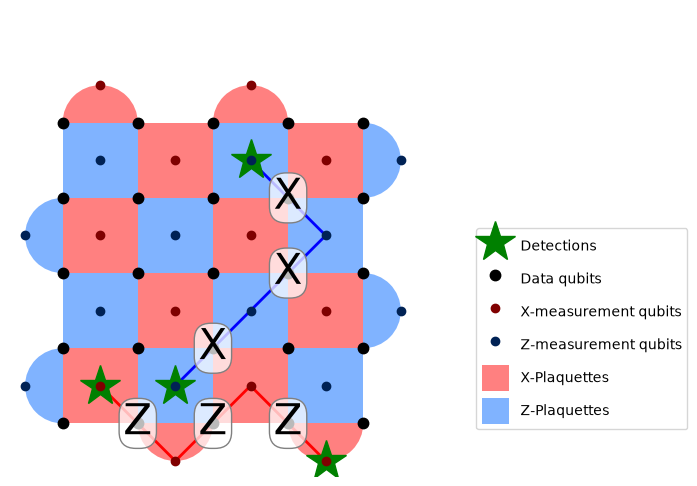

In [23]:
# Error line in the middle of the code
errors = np.array([
    ["I", "I", "I", "I", "I"],
    ["I", "I", "I", "X", "I"],
    ["I", "I", "I", "X", "I"],
    ["I", "I", "X", "I", "I"],
    ["I", "Z", "Z", "Z", "I"],
])

# X errors on the horizontal line (you can change to Z to see the difference and/or try to move the line up or down)
# errors = np.array([
#     ["I", "I", "I", "I", "I"],
#     ["I", "I", "I", "I", "I"],
#     ["X", "X", "X", "X", "X"],
#     ["I", "I", "I", "I", "I"],
#     ["I", "I", "I", "I", "I"],
# ])

# X errors on the vertical line (again you can change to Z and/or move the line left or right)
# errors = np.array([
#     ["I", "I", "X", "I", "I"],
#     ["I", "I", "X", "I", "I"],
#     ["I", "I", "X", "I", "I"],
#     ["I", "I", "X", "I", "I"],
#     ["I", "I", "X", "I", "I"],
# ])

# Closed loop of errors
# errors = np.array([
#     ["I", "I", "I", "I", "I"],
#     ["I", "I", "X", "X", "I"],
#     ["I", "X", "I", "I", "X"],
#     ["I", "X", "X", "X", "X"],
#     ["I", "I", "I", "I", "I"],
# ])

# Make your own error pattern here
# errors = np.array([
#     ["I", "I", "I", "I", "I"],
#     ["I", "I", "I", "I", "I"],
#     ["I", "I", "I", "I", "I"],
#     ["I", "I", "I", "I", "I"],
#     ["I", "I", "I", "I", "I"],
# ])

# Random errors
# errors = np.random.choice(["I", "X", "Y", "Z"], size=(11,11), p=[0.85, 0.05, 0.05, 0.05])

display(Markdown(filename="markdown_files/surface_code_error_diagram.md"))
plot_pauli_errors_and_their_syndromes(errors)

---

**Bonus:**

As you may have noticed, a string of either Pauli X or Z errors only trigger syndromes at their ends. And if a Pauli Z (X) string ends at the left or right (top or bottom) edge of the code it doesn't trigger any syndromes at that endpoint. This can be used to decode which error caused the syndrome by viewing the triggered syndromes as endpoints of Pauli X and Z strings and then calculating what the minimum number of Pauli's needed to explain the syndrome is and checking if that would also have caused a flip of the observable of the code.

This is exactly what the Minimum Weight Pefect Matching decoder (MWPM) and in turn the `PyMatching` library does. This idea can also be extended to the regime where errors also occur on gates and measurement operations - extending the problem into 3d. The `stim` library already comes with the functionality to display how this 3d graph problem looks. Below you will find the code to generate the graph used by the MWPM decoder for any distance surface code with a generic noise model.

In [24]:
surface_code_circuit = stim.Circuit.generated(
    "surface_code:rotated_memory_z",
    rounds=3,
    distance=3,
    # Set any of these error types to zero to disable them from showing up in the graph
    before_round_data_depolarization=0.001, # With probability p, place a random Pauli error on a given data qubit before each round
    after_clifford_depolarization=0.001, # With probability p, apply a random Pauli error after each gate on the qubits used by that gate (excluding resets and measurements)
    after_reset_flip_probability=0.001, # With probability p, flip the state of the qubit (apply X if the qubit was reset into the Z-basis and Z if it was reset into the X-basis)
    before_measure_flip_probability=0.01 # With probability p, flip the result of a qubit measurement
)

# Make a html file for interactive 3d viewing, easier to understand the structure of the graph compared to the 2d projection below
# The file is stored in the current working directory and can be opened in a web browser
with open("surface_code_circuit_decoder_graph.html", "w") as f:
    f.write(str(surface_code_circuit.detector_error_model(decompose_errors=True).diagram("matchgraph-3d-html")))

display(Markdown(filename="markdown_files/pymatching_graph.md"))

# Uncomment the line below to see the 2d projection of the decoder graph in the notebook
# surface_code_circuit.detector_error_model(decompose_errors=True).diagram("matchgraph-svg")

<div style="font-size: 1.18em; line-height: 1.3">

The output of this cell is saved to a html file named `surface_code_circuit_decoder_graph.html` which allows you to pan around in 3d and get a better understanding of the graph. The file can be found in the same directory as this notebook and be opened in a web-browser.

</div>

<div style="font-size: 1.18em; line-height: 1.3; border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #7e57c2; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🧠 How to read the 3d graph</h4>

- The 3 dimensions are the two spatial dimensions of the surface code (seen directly in the above graph) and a time dimension moving away from the point of view in the above graph.
- The black dots in the code represent the parity check detectors placed throughout the code (the stabilizers).
- The lines that connect the dots represent the errors that can occur in the code based on the selected noise. Each error is either a connection between two detectors (black dots) or a connection between a detector and outside of the code (representing errors that will only trigger one syndrome measurement).
- The red lines are just like the black lines except that if an odd number of them is used in the decoding process it signals that the observable of the code has been flipped.

</div>

### Exercise 3 - What happens to non-Pauli errors

So far, we have only looked at what a Pauli errors does to the syndromes but what do you think happens if the error is not a Pauli error? Take for example a Hadamard error on the data qubit at index location 2.

$$
H = \frac{1}{\sqrt{2}}\begin{pmatrix}
1 & 1 \\
1 & -1
\end{pmatrix}
$$

Let's start by creating a distance 3 surface code with no noise of its own as we will be adding errors manually for this exercise:

In [25]:
distance = 3

surface_code_circuit = stim.Circuit.generated(
    "surface_code:rotated_memory_x",
    distance=distance,
    rounds=2 # Don't change this
)
# surface_code_circuit.diagram("timeslice-svg", rows=1) # Uncomment to see the circuit diagram

And define some helper functions for adding the error and retrieving the syndrome that results from the added error (you do not need to understand how this function works but are of course welcome to take a look if you are interested):

In [26]:
def add_gate_error_to_data_qubit(circ: stim.Circuit, gate: str, qubit_idx: int) -> tuple[stim.Circuit, int]:
    """
    Adds a gate error to a specific data qubit between the first and second round of stabilizer measurements.

    Args:
        circ (stim.Circuit): The original quantum circuit.
        gate (str): The gate error to add (e.g., "H", "X", "Y", "Z").
        qubit_idx (int): The index of the data qubit to which the error will be added. The data qubits are 0-indexed starting at the top-left corner and counting left to right from top to bottom.
    
    Returns:
        tuple: A tuple containing:
            - stim.Circuit: A new circuit with the specified gate error added at the appropriate location.
            - int: The distance of the surface code.
    """
    new_circ = stim.Circuit()
    data_qubits = []
    gate_has_been_added = False
    current_tick = 0
    # Go one operation at a time through the circuit
    for op in circ:
        # Make sure each operation is copied to the new circuit
        new_circ.append(op)
        # Look at the qubit coordinates to identify the data qubits
        if op.name == "QUBIT_COORDS":
            x, y = op.gate_args_copy()
            # Check if it is a data qubit
            if x % 2 == 1 and y % 2 == 1:
                data_qubits.append((op.targets_copy()[0]))
        # Keep track of the current tick
        if op.name == "TICK":
            current_tick += 1
        # Add the gate error after the 8th tick (after the first round of stabilizer measurements have been performed)
        if current_tick == 8 and not gate_has_been_added:
            # Add the gate error to the specified data qubit
            new_circ.append(gate, data_qubits[qubit_idx])
            # Add a TICK after the gate error so the gate will have it's own tick
            new_circ.append("TICK")
            # Mark the gate as added so we don't add it again
            gate_has_been_added = True
    # Get the distance of the code assuming a square surface code
    distance = int(np.sqrt(len(data_qubits))) 
    return new_circ, distance

def get_syndrome_from_gate_error(circ: stim.Circuit, gate: str, qubit_idx: int, shots: int) -> np.ndarray:
    """
    Gets the syndrome resulting from adding a specific gate error to a specific data qubit in a surface code circuit.

    Args:
        circ (stim.Circuit): The original quantum circuit.
        gate (str): The gate error to add (e.g., "H", "X", "Y", "Z").
        qubit_idx (int): The index of the data qubit to which the error will be added. The data qubits are 0-indexed starting at the top-left corner and counting left to right from top to bottom.
        shots (int): The number of shots to simulate.
    
    Returns:
        np.ndarray: A binary array of shape (shots, num_syndromes) containing the effect of the gate error on the syndrome measurements.
    """
    circ_with_error, distance = add_gate_error_to_data_qubit(circ, gate, qubit_idx)
    num_synd = distance**2 - 1 
    # Use the regular sampler which gives us the measurement outcomes instead of the detector events
    sampler = circ_with_error.compile_sampler()
    measurements = sampler.sample(shots=shots)
    # Retrieve the measurements from the two rounds
    first_round_syndrome = measurements[:, :num_synd]
    second_round_syndrome = measurements[:, num_synd:2*num_synd]
    # The syndrome is the difference between the two rounds (indicates any error - like the one we added - that occurred between the two rounds)
    syndromes_change = first_round_syndrome ^ second_round_syndrome
    return syndromes_change

This is how the circuit looks after a Hadamard error has been added to the data qubit at index 2 (see tick 8)

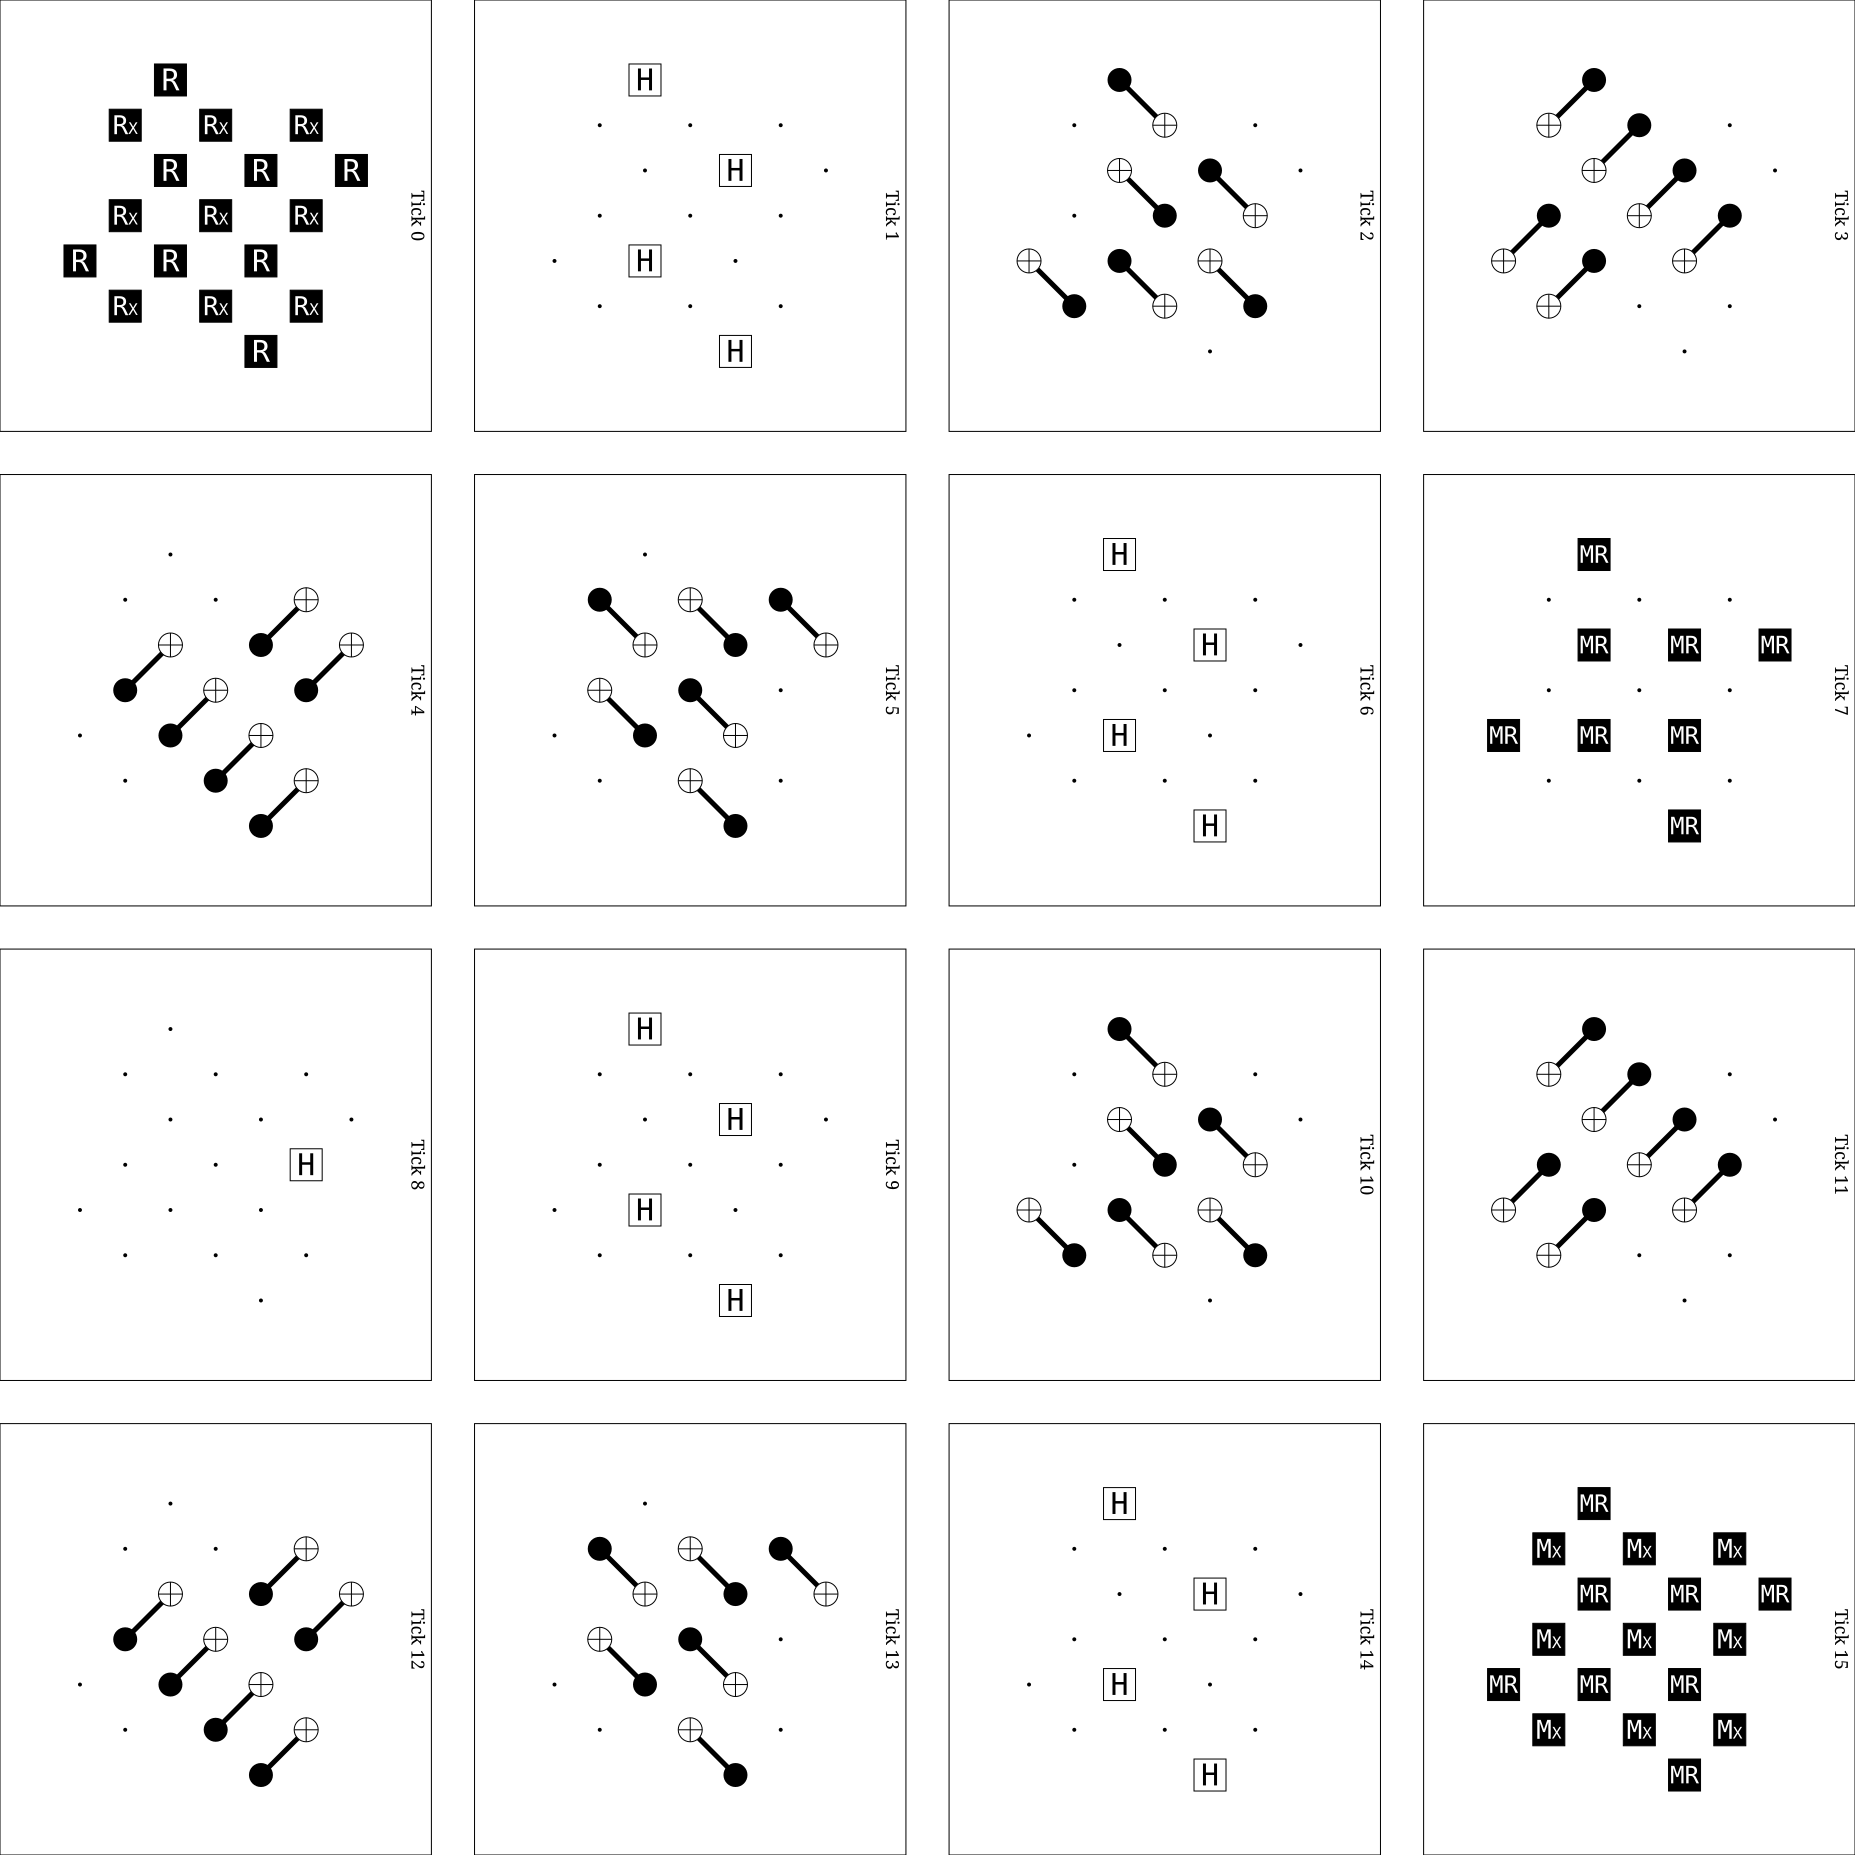

In [27]:
surface_code_circuit_with_error, _ = add_gate_error_to_data_qubit(surface_code_circuit, "H", qubit_idx=5)
surface_code_circuit_with_error.diagram("timeslice-svg", rows=None) # The hadamard error is added to the data qubit at index 2 at tick 8
# surface_code_circuit_with_error.diagram("timeslice-svg", tick=range(8,8+1)) # Uncomment to only see tick 8

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #4CAF50; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🖥️ Exercise</h4>

First check how the syndromes look if the error is a Pauli error [X, Y, Z], using the `get_syndrome_from_gate_error` function.

- Is the syndrome always the same or does it change from shot to shot?

Next check how the syndrome looks if you use a non-Pauli error like the Hadamard gate H.

- Again, is the syndrome always the same or does it change from shot to shot?

- Does it have anything in common with the syndromes you saw from the Pauli errors?

- What about other non-Pauli gates?

<details style="margin: 10px 0; padding: 8px 12px; border: 1px dashed var(--jp-border-color2, #aaa); border-radius: 6px;">
  <summary><strong>💡 Hint</strong></summary>

Can you decompose your non-Pauli gate into a linear combination of Pauli gates? if yes, how would it look?

</details>

</div>

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #ccc; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>📝 Answer:</h4>

Your answer goes here...

</div>

In [28]:
# Your code goes here

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #4CAF50; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🖥️ Exercise</h4>

In practice a small error probably happens to all the qubits in the code - something like $R_Z(\theta)$ or $R_X(\theta)$ with $\theta$ being a small angle - yet the surface code is only supposed to be able to handle a small number of errors, not an error on every data qubits. Using what you have just learned, can you explain why the surface code is still able to handle this case?

</div>

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #ccc; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>📝 Answer:</h4>

Your answer goes here...

</div>

## Deep dive (Ekstra)

This is the deep dive section. You do not strictly need to understand this section to do the project but going through this part of the notebook will give you a much deeper understanding of how the surface code and other stabilizer QECCs work.

### Understanding the stabilizers of the code

Up until this point we have looked at the stabilizers of the surface code as if they were a static thing in the code. This works if we are primarily looking at data qubit errors between quantum error correction cycles, but it breaks down when we start to consider errors in the middle of a quantum error correction cycle.

Let's start by creating the surface code in both the logical X and Z basis:

In [31]:
# You can change the number of rounds and distance to see how the stabilizes look at various code sizes
rounds = 3
distance = 3
# We will not be using any noise model here as we just want to see the evolution of the stabilizers and they are the same no matter the noise model
surface_code_circuit_x = stim.Circuit.generated(
    "surface_code:rotated_memory_x",
    rounds=rounds,
    distance=distance,
)
surface_code_circuit_z = stim.Circuit.generated(
    "surface_code:rotated_memory_z",
    rounds=rounds,
    distance=distance,
)

Now instead of using the `timeslice-svg` diagram that we have used previously, we will instead be using the `detslice-with-ops-svg` which does the same except also draws the stabilizers of the code at each time step (tick).

Here we have done it for the X-basis variant of the surface code - feel free to take a look at how it looks for the Z-basis variant of the code.

<div style="font-size: 1.18em; line-height: 1.3; border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #7e57c2; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🧠 How to read the diagram</h4>

The colored blocks in this diagram indicates the stabilizers of the code at each timestep. Each of the stabilizers is red or blue at the locations where it meets a physical qubit - red tells us that it stabilizes the physical qubit with a Pauli X while blue tells us that it stabilizes with a Pauli Z. At tick 0, we see that the data qubits which are reset to $\ket0$ (**$R$**) are stabilized with the color blue since $Z\ket0 = \ket0$, while the ones that are reset to $\ket+$ (**$R_X$**) are stabilized by the color red since $X\ket+ = \ket+$.

</div>

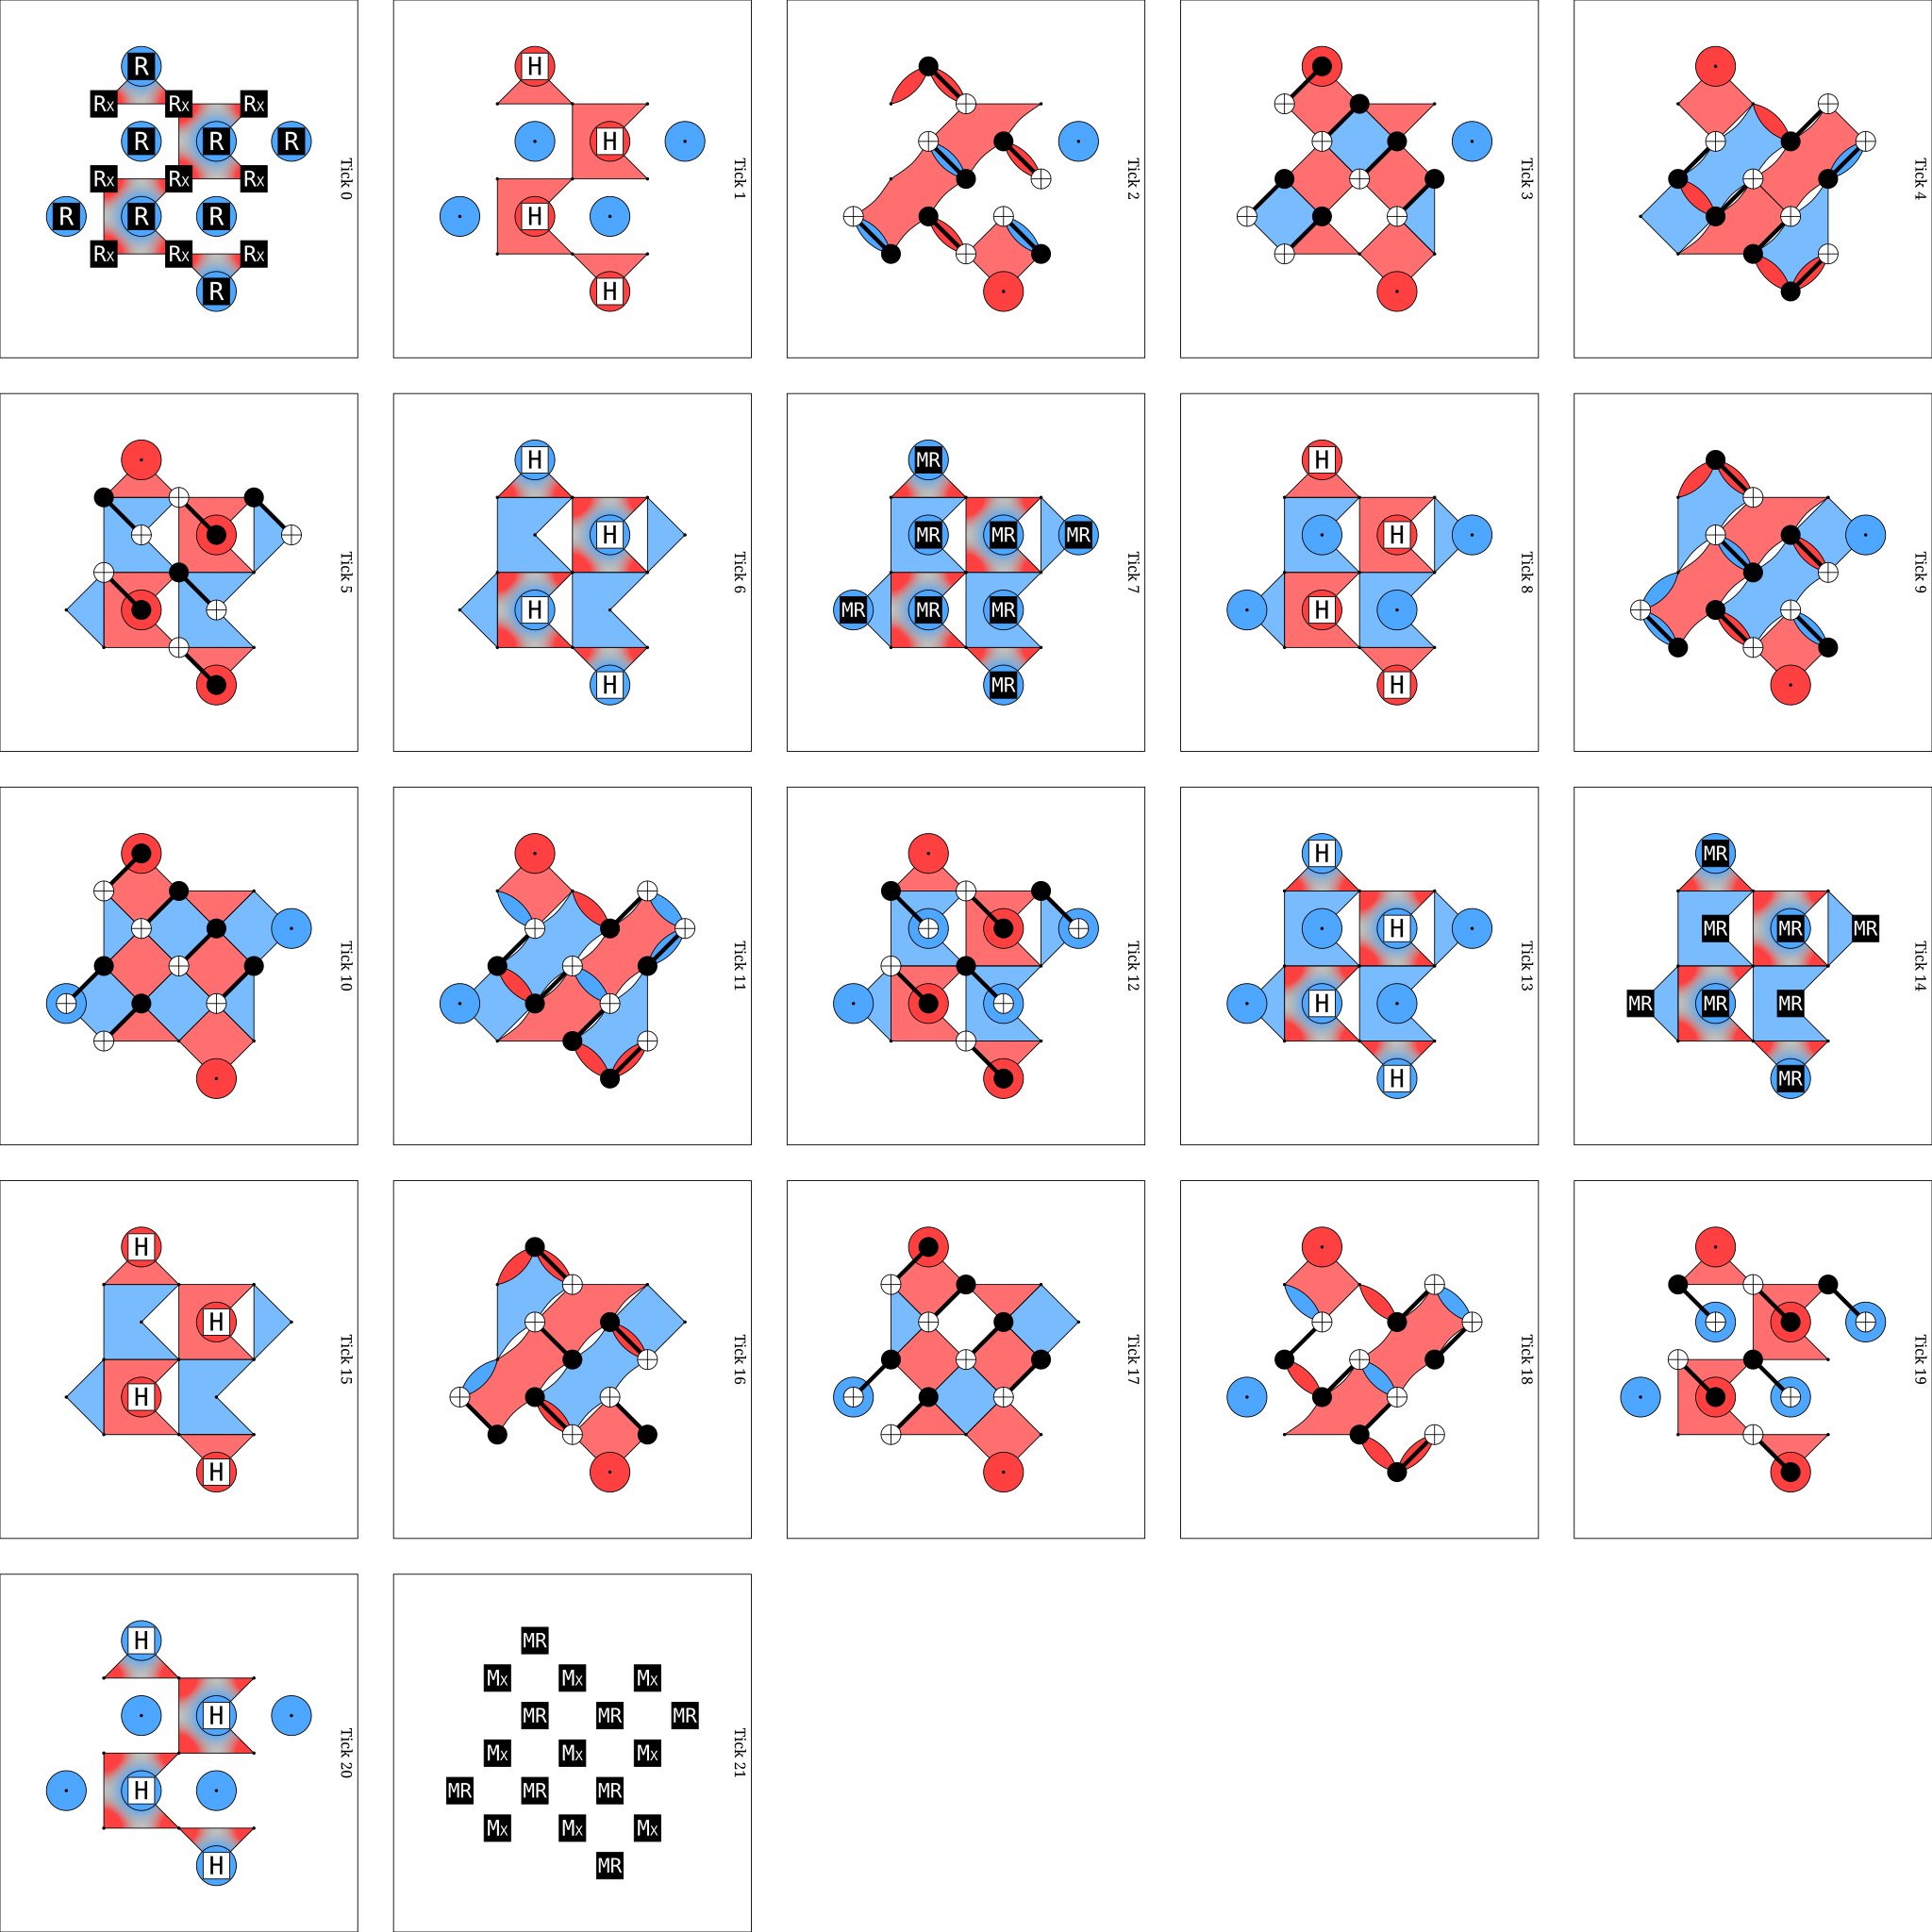

In [32]:
display(Markdown(filename="markdown_files/detector_slices_diagram.md"))
surface_code_circuit_x.diagram("detslice-with-ops-svg", rows=None)

This shows all the stabilizers, which can be a bit much to look at all at once. Luckily, `stim` gives us the option to only show a selection of stabilizers, using the `filter_coord` argument in the `.diagram()` function.

Below you will find a few subsets of the stabilizers, but you are of course also welcome to choose which to show yourself.

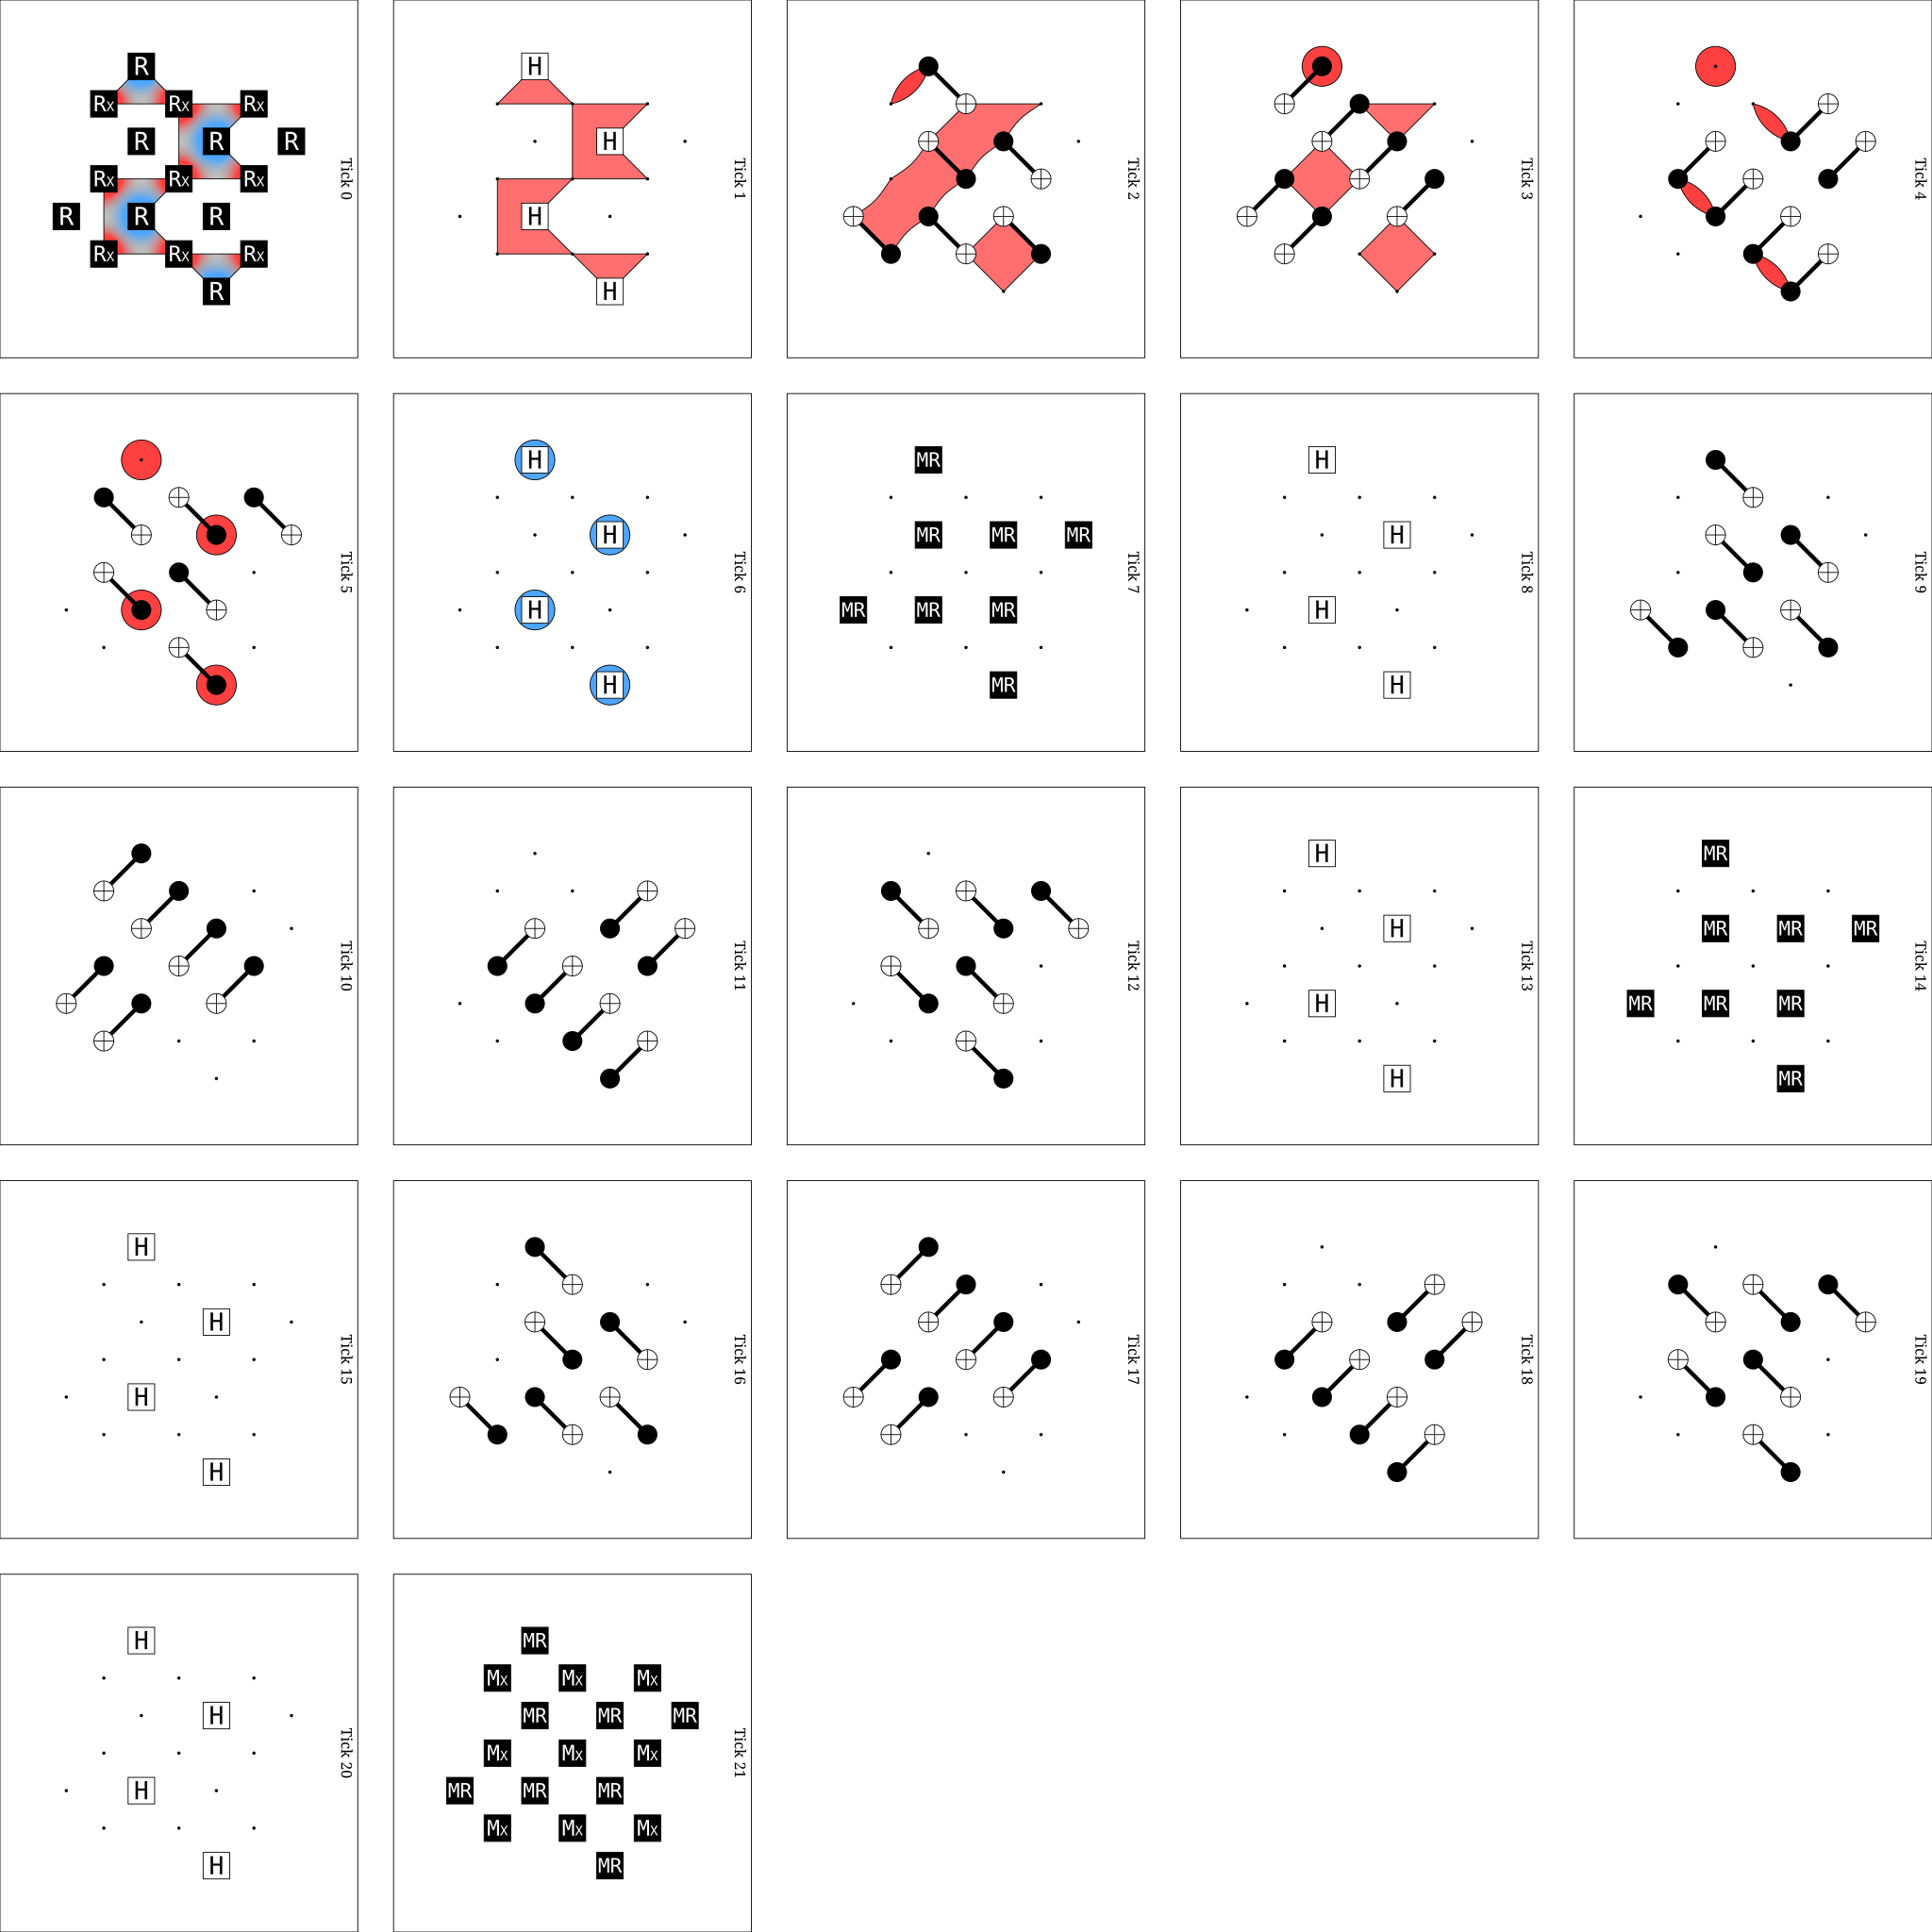

In [33]:
num_stab = distance**2 - 1  # Number of stabilizers in each round

# In the first round only halve the stabilizers are measured as the other halve are not yet deterministic (Can you see why?)
initialization_stabilizers = [f"D{i}" for i in range(num_stab // 2)]  # First round stabilizers [D0, D1, D2, D3]

# The stabilizers measured for a single round of stabilizer measurements - you may notice that they actually span two rounds (Why do you think that is?)
round_n = 0 # Change this to see stabilizers from different rounds (0-indexed)
round_n_stabilizers = [f"D{i + int((round_n + 1/2) * num_stab)}" for i in range(num_stab)]

surface_code_circuit_x.diagram("detslice-with-ops-svg", filter_coords=initialization_stabilizers, rows=None)

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #4CAF50; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🖥️ Exercise</h4>

- Why do we only measure halve of the stabilizers after initialization of the code? And why are the stabilizers we chose to measure different dependending on whether we initialize the logical state in the $\ket0$ state or the $\ket+$ state?

- For the internal rounds of the code we measure all $L^2-1$ stabilizers. The stabilizers evolution does however span two rounds and are thus measured twice, why is that?

- For the last round of stabilizer measurements `round_n = rounds-1`, we again only measure halve of the stabilizers, why are we not interested in the other halve?

</div>

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #ccc; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>📝 Answer:</h4>

Your answer goes here...

</div>

---

### Logical observables

Just like `stim` lets us inspect the evolution of the stabilizers of the code, we can also inspect the evolution of the observable. In the surface code the observable in the X (Z) basis spans the entire height (width) of the QECC. The name of the observable is `L0` (if we had more observables they would be called `L1`, `L2`, etc.).

Try looking at how the observable is different depending on whether we are looking in the X or Z basis:

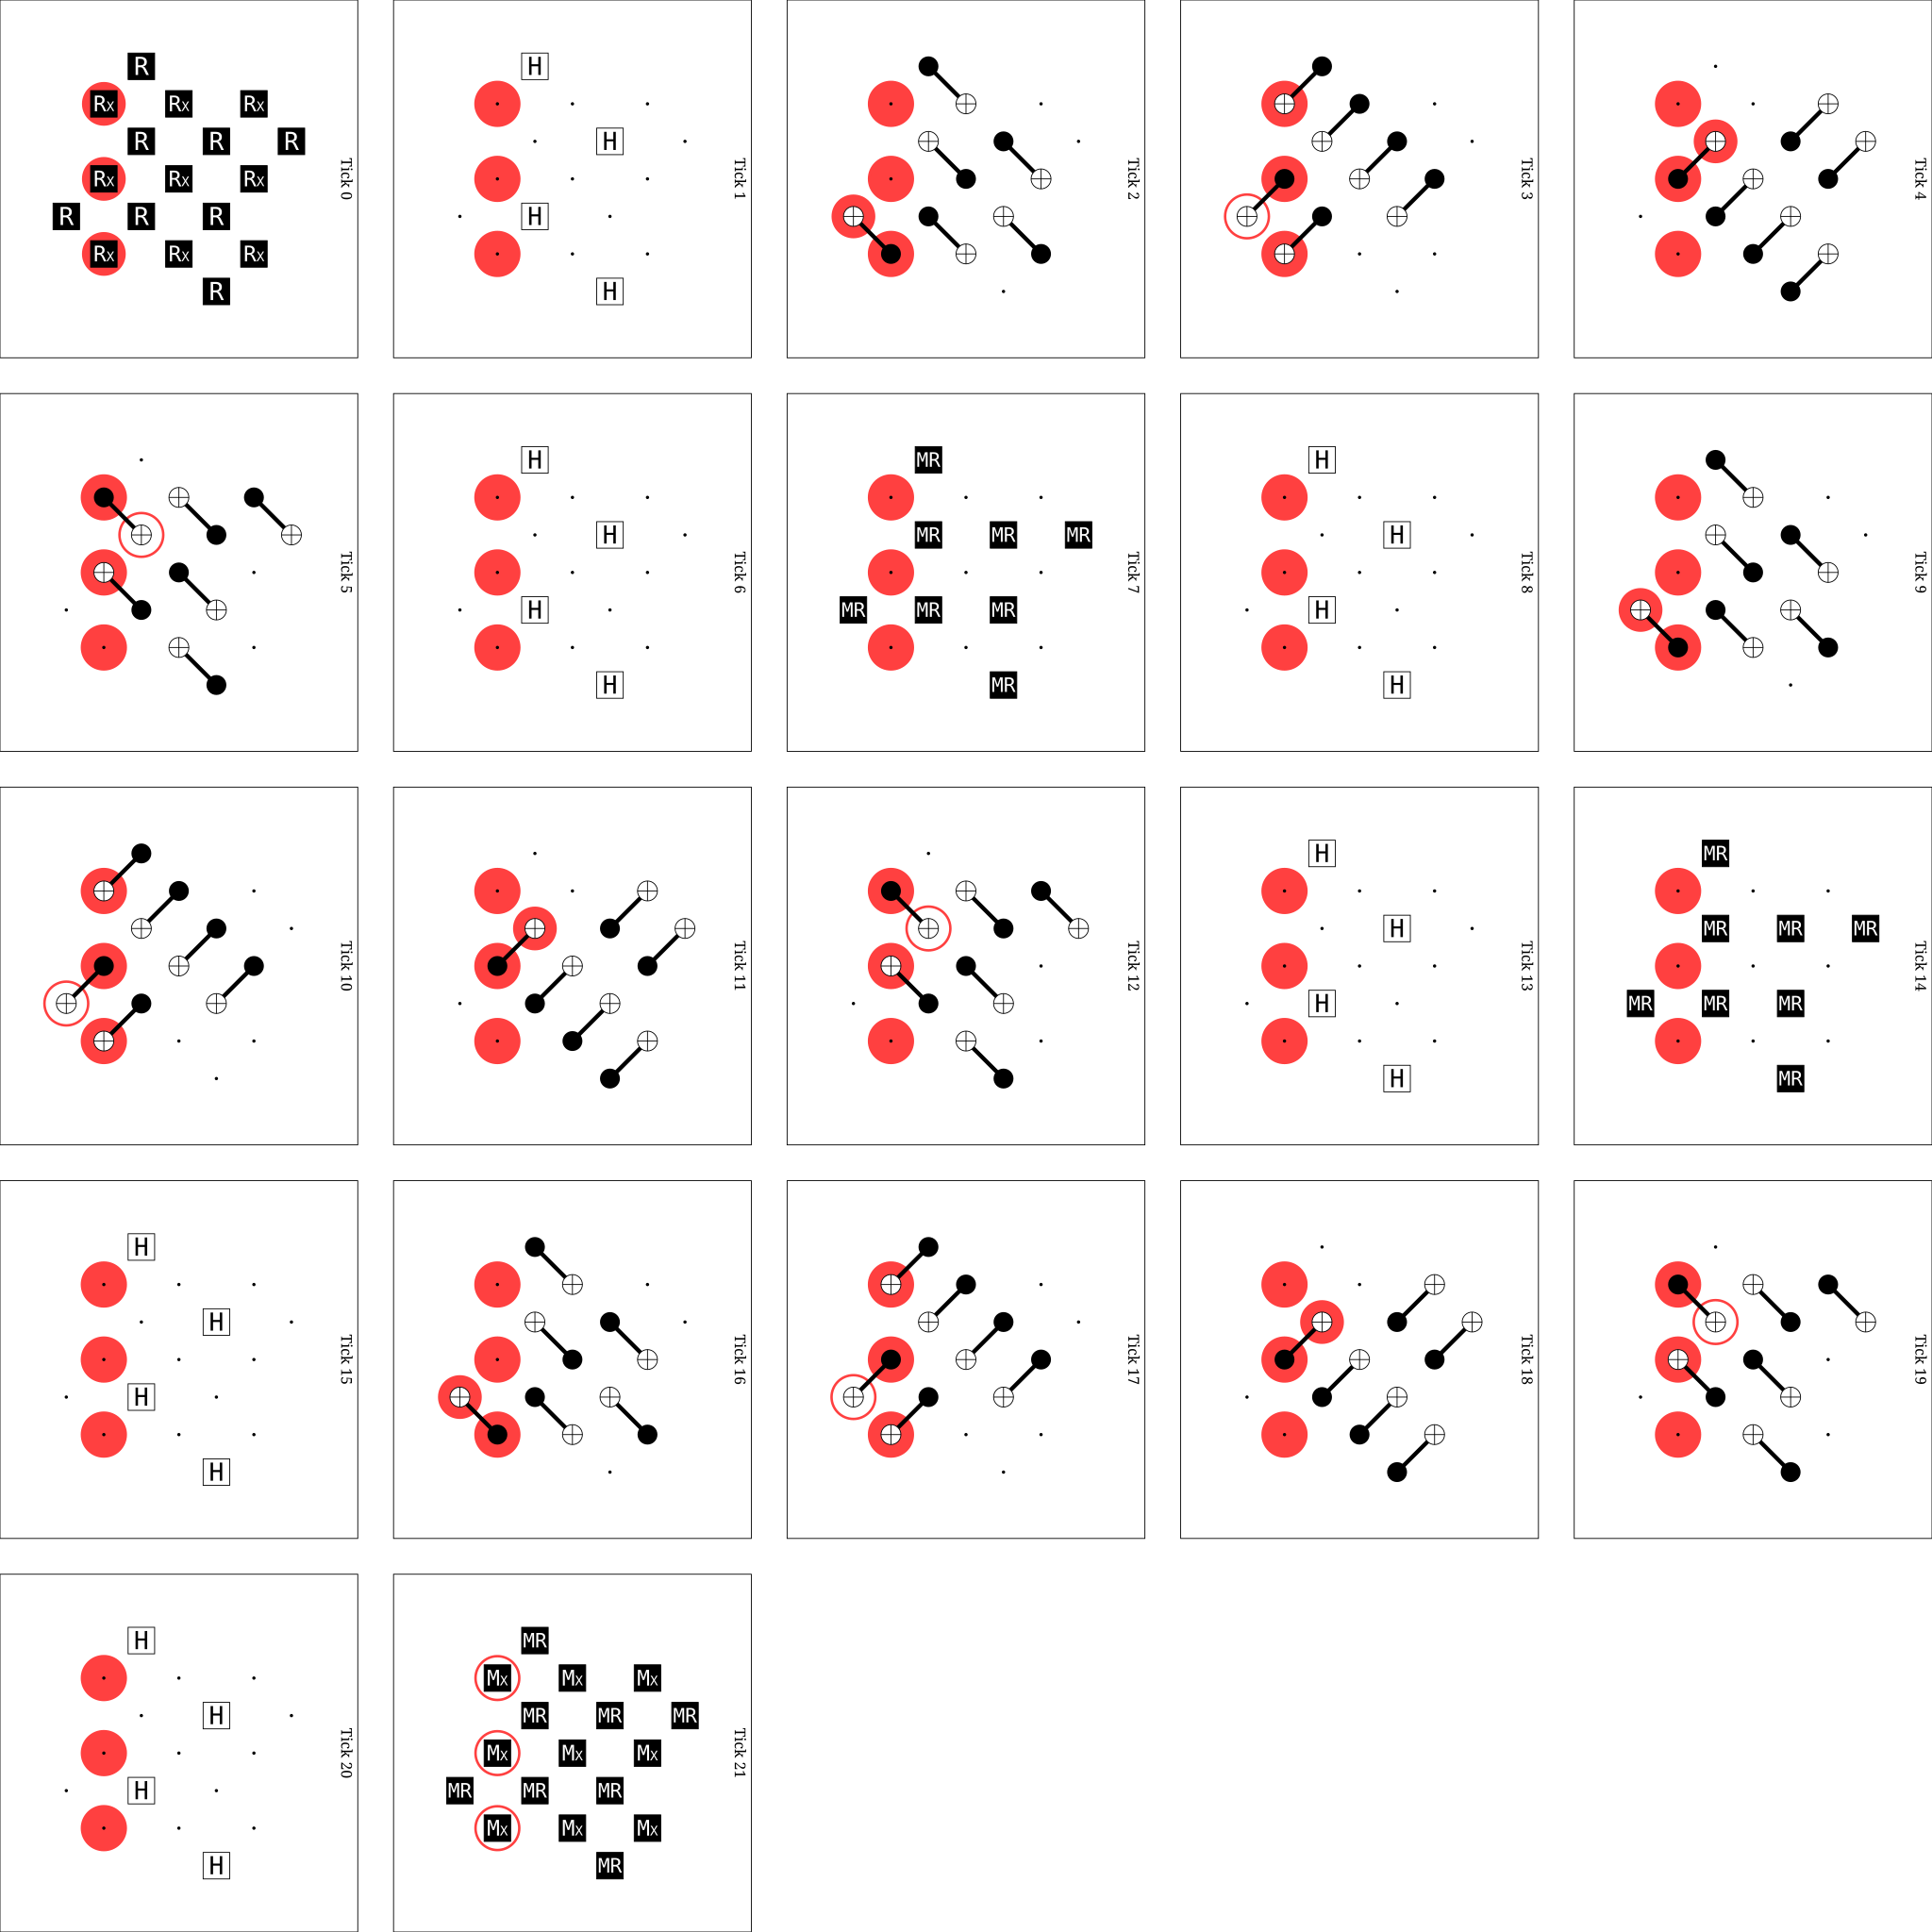

In [34]:
surface_code_circuit_x.diagram("detslice-with-ops-svg", filter_coords=['L0'], rows=None)

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #4CAF50; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🖥️ Exercise</h4>

- In the case of the stabilizers we used ancilliary qubits to measure their values, Why do we not do the same in the case of the observable? What would be the architectual challenges be if we wanted to measure them in the same way (especially for $L$)?

- If we don't use ancillary qubits to measure the observable, how do we then get the collapsed eigenvalue of the observable?

</div>

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #ccc; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>📝 Answer:</h4>

Your answer goes here...

</div>